# SDF-GS Refine - fresh, fully-visualized Paperspace run

Self-contained notebook. Runs the whole pipeline on a **Paperspace A6000 GPU** with:
pinned dependency versions (numpy ABI guard), Kaggle dataset download via `kagglehub`
(cleaned up at the end), the confirmed **tunnel-defect fix** (orientation-disambiguated
surface supervision), Marching Cubes at **160 and 256**, and an **inline visualization of
every step** so you can visually debug.

## How to run
1. Upload **this single file** to a Paperspace GPU (A6000) notebook, Python kernel.
2. Run **cell by cell** (`Shift+Enter`), top to bottom.
3. If cell 1 stops with `RESTART KERNEL NOW` - restart the kernel **once**, then re-run from the top (fast).
4. Every stage saves a `step*.png` into `run_artifacts/.../` and renders it inline below the cell.

## What each visual tells you
| visual | file | what to check |
|---|---|---|
| 1. Gaussian render | `step1_pretrained_render.png` | does the pretrained 3DGS look like the bear? |
| 2. Surface samples 3D | `step2_surface_samples.png` | sample cloud = the shape (surface points are correct) |
| 3. Samples overlaid on render | `step3_samples_overlay.png` | 1:1 projection matches the picture |
| 4. SDF convergence | `step4*` | mesh gets born cleanly, no egg/blobs |
| 5. Extracted mesh | `step5_extracted_mesh.png` | 3-view of MC output |
| 6. Mesh on render | `step6_mesh_overlay.png` | silhouette matches the bear |
| 7. GT (best effort) | `step7_gt_overlay.png` | optional DTU ground-truth comparison |

`run_artifacts/<scan>-<hash>/` keeps `01_surface_samples.pt`, `train_checkpoint.pt`,
meshes and `results.json`.


In [1]:
# ============ 1. ENVIRONMENT - pinned deps, numpy-ABI guard, GPU check ============
import os, sys, subprocess, importlib.util, json, hashlib, time, gc
from pathlib import Path

NEED_RESTART = False

def pin(name, pip_name, pin=None, import_name=None):
    # Install-if-missing / pin a package. Only touches numpy in-place when needed.
    global NEED_RESTART
    mod = import_name or name
    spec = f"{pip_name}=={pin}" if pin else pip_name
    if importlib.util.find_spec(mod) is None:
        print(f"  + installing {spec}")
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", spec], check=True)
        if mod == "numpy":
            NEED_RESTART = True
        return
    if pin is not None and mod == "numpy":
        cur = __import__("numpy").__version__
        if cur != pin:
            print(f"  ~ numpy is {cur}, want {pin} -> downgrading")
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", spec], check=True)
            NEED_RESTART = True
        else:
            print(f"  + numpy=={cur} OK")

print("python:", sys.version.split()[0])
pin("numpy", "numpy", "1.26.4")
pin("scipy", "scipy", "1.13.1")
pin("trimesh", "trimesh", "4.4.9")
pin("plyfile", "plyfile", "1.0.3")
pin("networkx", "networkx", "3.3")
pin("sklearn", "scikit-learn", "1.5.2")
pin("skimage", "scikit-image", "0.24.0")
pin("matplotlib", "matplotlib", "3.9.2")
pin("PIL", "pillow", "10.4.0")
pin("kagglehub", "kagglehub", "0.3.4")

if importlib.util.find_spec("torch") is None:
    print("  + torch missing -> installing cu121 build")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "torch",
                    "--index-url", "https://download.pytorch.org/whl/cu121"], check=True)

if not NEED_RESTART:
    abi = ("import numpy as np, torch, scipy, trimesh, plyfile, networkx, skimage, sklearn;"
           "print('ABI OK', np.__version__, torch.__version__)")
    r = subprocess.run([sys.executable, "-c", abi], capture_output=True, text=True)
    print("ABI smoke:", (r.stdout or r.stderr).strip()[-300:])
    if r.returncode != 0:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "numpy==1.26.4"], check=True)
        NEED_RESTART = True

if NEED_RESTART:
    sys.exit(">>> RESTART KERNEL NOW (numpy ABI changed). Restart, then re-run this notebook from the top.")

print("Environment ready.")
import numpy as np
import torch
print("torch :", torch.__version__)
print("cuda  :", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"gpu   : {p.name}  {p.total_memory / 2**30:.1f} GB")
torch.manual_seed(42)
np.random.seed(42)


python: 3.11.7
  + numpy==1.26.4 OK
ABI smoke: ABI OK 1.26.4 2.1.1+cu121
Environment ready.
torch : 2.1.1+cu121
cuda  : True
gpu   : NVIDIA RTX A6000  47.5 GB


In [2]:
# ============ 2. MATERIALIZE the exact `src/` package used by the reference implementation ============
# Self-contained: the notebook embeds the full source of every module of the
# reference repo and re-creates a real `src/` package next to it, then imports
# it normally - so what is already installed on the Paperspace box does not matter.

NB_ROOT = Path.cwd().resolve()
SRC_DIR = NB_ROOT / "src"
SRC_DIR.mkdir(exist_ok=True)
(SRC_DIR / "__init__.py").write_text("", encoding="utf-8")

SRC_FILES = {"utils.py": "\"\"\"\nutils.py\nBasic infra: seeding, device detection, config loading, simple logger.\nCaveman-simple: no external logging framework, just print with timestamps.\n\"\"\"\nimport os\nimport json\nimport random\nimport time\nimport numpy as np\nimport torch\n\n\ndef set_seed(seed: int = 42):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    return seed\n\n\ndef get_device():\n    if torch.cuda.is_available():\n        return torch.device(\"cuda\")\n    return torch.device(\"cpu\")\n\n\ndef log(msg: str):\n    ts = time.strftime(\"%H:%M:%S\")\n    print(f\"[{ts}] {msg}\")\n\n\ndef load_config(path: str) -> dict:\n    with open(path, \"r\") as f:\n        return json.load(f)\n\n\ndef ensure_dir(path: str):\n    os.makedirs(path, exist_ok=True)\n    return path\n\n\ndef check_tensor(name: str, t: torch.Tensor, raise_on_bad=True):\n    \"\"\"Basic NaN/Inf validation used throughout the pipeline (Section 12/13).\"\"\"\n    if t is None:\n        return\n    n_nan = torch.isnan(t).sum().item()\n    n_inf = torch.isinf(t).sum().item()\n    if n_nan or n_inf:\n        msg = f\"[VALIDATION FAILED] tensor '{name}' has {n_nan} NaN and {n_inf} Inf values (shape={tuple(t.shape)})\"\n        if raise_on_bad:\n            raise ValueError(msg)\n        else:\n            print(msg)\n    return n_nan == 0 and n_inf == 0\n", "gaussian.py": "\"\"\"\ngaussian.py\n\nLoads a PRETRAINED 3D Gaussian Splatting model (point_cloud.ply) and exposes\nthe Gaussian primitive attributes {mu_i, Sigma_i, alpha_i, c_i} exactly as\ndescribed in the paper Subbab 2.1 (\"SIGNED DISTANCE FIELD UNTUK MESH\nEXTRACTION DARI 3D GAUSSIAN SPLAT\").\n\nWe do NOT train 3DGS here. This module only LOADS an already-trained model.\n\nStandard 3DGS PLY schema (official Kerbl et al. 2023 implementation) stores:\n    x, y, z                    -> position (mean) mu_i               [raw]\n    nx, ny, nz                 -> unused placeholder normals (zeros)\n    f_dc_0..2                  -> SH degree-0 (DC) color coefficients [raw]\n    f_rest_0..K                -> SH higher-order coefficients        [raw]\n    opacity                    -> raw logit,      alpha_i = sigmoid(opacity)\n    scale_0..2                 -> raw log-scale,  s_i     = exp(scale)\n    rot_0..3                   -> raw quaternion, R_i     = quat_to_rotmat(normalize(rot))\n\nSigma_i = R_i S_i S_i^T R_i^T   (Kerbl et al. 2023, Sec 4 -- also paper Subbab 2.1)\n\"\"\"\nimport glob\nimport os\nimport numpy as np\nimport torch\nfrom plyfile import PlyData\n\n\ndef discover_point_clouds(root_dir: str):\n    \"\"\"\n    Auto-discovery of pretrained point_cloud.ply files under `root_dir`.\n    Matches the expected layout described by the user:\n        <root_dir>/<scan_name>/point_cloud/iteration_XXXXX/point_cloud.ply\n    but falls back to a recursive search for *any* point_cloud.ply if that\n    exact layout isn't found, so we never hard-code one scan/path.\n    Returns a dict: {scan_name: {iteration_number: path}\n    \"\"\"\n    results = {}\n    pattern = os.path.join(root_dir, \"*\", \"point_cloud\", \"iteration_*\", \"point_cloud.ply\")\n    matches = sorted(glob.glob(pattern))\n    if not matches:\n        # fallback: recursive search anywhere under root_dir\n        matches = sorted(glob.glob(os.path.join(root_dir, \"**\", \"*.ply\"), recursive=True))\n\n    for m in matches:\n        parts = m.replace(\"\\\\\", \"/\").split(\"/\")\n        scan_name = \"unknown_scan\"\n        iteration = -1\n        if \"point_cloud\" in parts:\n            pc_idx = parts.index(\"point_cloud\")\n            if pc_idx >= 1:\n                scan_name = parts[pc_idx - 1]\n            if pc_idx + 1 < len(parts) and parts[pc_idx + 1].startswith(\"iteration_\"):\n                try:\n                    iteration = int(parts[pc_idx + 1].split(\"_\")[-1])\n                except ValueError:\n                    iteration = -1\n        else:\n            scan_name = os.path.splitext(os.path.basename(m))[0]\n        results.setdefault(scan_name, {})[iteration] = m\n\n    return results\n\n\ndef pick_latest_iteration(scan_dict: dict):\n    \"\"\"From {iteration:int -> path} pick the path with the highest iteration.\"\"\"\n    best_it = max(scan_dict.keys())\n    return scan_dict[best_it], best_it\n\n\ndef quat_to_rotmat(q: torch.Tensor) -> torch.Tensor:\n    \"\"\"\n    q: (N,4) normalized quaternion (w,x,y,z) -> (N,3,3) rotation matrices.\n    Standard formula, same convention used by the official 3DGS codebase.\n    \"\"\"\n    w, x, y, z = q[:, 0], q[:, 1], q[:, 2], q[:, 3]\n    N = q.shape[0]\n    R = torch.zeros((N, 3, 3), dtype=q.dtype, device=q.device)\n    R[:, 0, 0] = 1 - 2 * (y * y + z * z)\n    R[:, 0, 1] = 2 * (x * y - w * z)\n    R[:, 0, 2] = 2 * (x * z + w * y)\n    R[:, 1, 0] = 2 * (x * y + w * z)\n    R[:, 1, 1] = 1 - 2 * (x * x + z * z)\n    R[:, 1, 2] = 2 * (y * z - w * x)\n    R[:, 2, 0] = 2 * (x * z - w * y)\n    R[:, 2, 1] = 2 * (y * z + w * x)\n    R[:, 2, 2] = 1 - 2 * (x * x + y * y)\n    return R\n\n\nclass GaussianModel:\n    \"\"\"\n    Holds pretrained 3DGS Gaussian attributes on `device`, exposing:\n        positions (mu)   : (N,3)\n        opacity   (alpha): (N,)   in (0,1), already sigmoid-activated\n        scales    (s)     : (N,3)  already exp-activated (world units)\n        rotations (quat)  : (N,4)  normalized (w,x,y,z)\n        colors    (c)     : (N,3)  SH DC term converted to RGB (view-independent\n                                     approximation -- see note in load())\n        covariance Sigma  : (N,3,3) computed lazily via `covariance()`\n    \"\"\"\n\n    def __init__(self):\n        self.positions = None\n        self.opacity = None\n        self.scales = None\n        self.rotations = None\n        self.colors = None\n        self.sh_rest = None\n        self.n_sh_rest = 0\n        self.source_path = None\n        self._Sigma = None\n        self._Sigma_inv = None\n\n    # ------------------------------------------------------------------ #\n    # Loading\n    # ------------------------------------------------------------------ #\n    @classmethod\n    def load_ply(cls, path: str, device=None):\n        device = device or torch.device(\"cpu\")\n        ply = PlyData.read(path)\n        v = ply[\"vertex\"]\n        names = v.data.dtype.names\n\n        def col(name):\n            return np.asarray(v[name], dtype=np.float32)\n\n        xyz = np.stack([col(\"x\"), col(\"y\"), col(\"z\")], axis=1)\n\n        if \"opacity\" not in names:\n            raise ValueError(f\"'{path}' has no 'opacity' field -- not a valid 3DGS point_cloud.ply\")\n        opacity_raw = col(\"opacity\")\n\n        scale_names = sorted([n for n in names if n.startswith(\"scale_\")],\n                              key=lambda s: int(s.split(\"_\")[-1]))\n        rot_names = sorted([n for n in names if n.startswith(\"rot_\")],\n                            key=lambda s: int(s.split(\"_\")[-1]))\n        if len(scale_names) != 3 or len(rot_names) != 4:\n            raise ValueError(\n                f\"'{path}': expected 3 scale_* and 4 rot_* fields, got \"\n                f\"{len(scale_names)} and {len(rot_names)} -- unexpected 3DGS PLY schema\"\n            )\n        scale_raw = np.stack([col(n) for n in scale_names], axis=1)\n        rot_raw = np.stack([col(n) for n in rot_names], axis=1)\n\n        # SH DC term -> base color (sigma_c(0) SH constant folded in, standard 3DGS convention)\n        SH_C0 = 0.28209479177387814\n        if all(f\"f_dc_{i}\" in names for i in range(3)):\n            f_dc = np.stack([col(f\"f_dc_{i}\") for i in range(3)], axis=1)\n            colors = 0.5 + SH_C0 * f_dc\n        else:\n            # no SH color available -> fall back to mid-gray, flagged in validation report\n            colors = np.full((xyz.shape[0], 3), 0.5, dtype=np.float32)\n\n        rest_names = sorted([n for n in names if n.startswith(\"f_rest_\")],\n                             key=lambda s: int(s.split(\"_\")[-1]))\n        sh_rest = np.stack([col(n) for n in rest_names], axis=1) if rest_names else None\n\n        m = cls()\n        m.source_path = path\n        m.positions = torch.tensor(xyz, device=device)\n        m.opacity = torch.sigmoid(torch.tensor(opacity_raw, device=device))\n        m.scales = torch.exp(torch.tensor(scale_raw, device=device))\n        quat = torch.tensor(rot_raw, device=device)\n        m.rotations = torch.nn.functional.normalize(quat, dim=-1)\n        m.colors = torch.clamp(torch.tensor(colors, device=device), 0.0, 1.0)\n        m.sh_rest = torch.tensor(sh_rest, device=device) if sh_rest is not None else None\n        m.n_sh_rest = sh_rest.shape[1] if sh_rest is not None else 0\n        return m\n\n    # ------------------------------------------------------------------ #\n    # Geometry\n    # ------------------------------------------------------------------ #\n    def covariance(self, eps: float = 1e-8):\n        \"\"\"Sigma_i = R_i S_i S_i^T R_i^T  (paper Subbab 2.1, Kerbl et al. 2023).\"\"\"\n        if self._Sigma is not None:\n            return self._Sigma, self._Sigma_inv\n        R = quat_to_rotmat(self.rotations)                       # (N,3,3)\n        S = self.scales                                          # (N,3)\n        S2 = torch.diag_embed(S * S + eps)                       # (N,3,3)\n        Sigma = R @ S2 @ R.transpose(1, 2)                        # (N,3,3)\n        Sigma = Sigma + eps * torch.eye(3, device=Sigma.device).unsqueeze(0)\n        Sigma_inv = torch.linalg.inv(Sigma)\n        self._Sigma, self._Sigma_inv = Sigma, Sigma_inv\n        return Sigma, Sigma_inv\n\n    def density_at(self, x: torch.Tensor, idx: torch.Tensor = None):\n        \"\"\"\n        Full 3D anisotropic Gaussian density evaluated at points `x`.\n        x  : (N,3)  one query point per selected Gaussian (paired evaluation,\n             used by the transmittance-crossing estimator -- see transmittance.py)\n        idx: (N,) indices into this model selecting which Gaussian each x\n             corresponds to. If None, assumes x[i] queries gaussian i for all i\n             (i.e. len(x) == len(self)).\n        Returns G_i(x): (N,)  (paper Eq. in Subbab 2.1 / Persamaan 3.2 term)\n        \"\"\"\n        _, Sigma_inv = self.covariance()\n        mu = self.positions if idx is None else self.positions[idx]\n        Sinv = Sigma_inv if idx is None else Sigma_inv[idx]\n        d = (x - mu).unsqueeze(-1)                                # (N,3,1)\n        quad = torch.einsum(\"nij,njk,nkl->nil\", d.transpose(1, 2), Sinv, d).squeeze(-1).squeeze(-1)\n        return torch.exp(-0.5 * quad)\n\n    def filter_by_opacity(self, min_opacity: float = 0.05):\n        \"\"\"\n        Mitigation (1) from paper Subbab 3.5: drop Gaussians with alpha_i < 0.05\n        before transmittance computation (marginal contribution, adds noise to\n        crossing estimate). Returns a NEW filtered GaussianModel + boolean mask.\n        \"\"\"\n        mask = self.opacity >= min_opacity\n        out = GaussianModel()\n        out.source_path = self.source_path\n        out.positions = self.positions[mask]\n        out.opacity = self.opacity[mask]\n        out.scales = self.scales[mask]\n        out.rotations = self.rotations[mask]\n        out.colors = self.colors[mask]\n        out.sh_rest = self.sh_rest[mask] if self.sh_rest is not None else None\n        out.n_sh_rest = self.n_sh_rest\n        return out, mask\n\n    def clone_detached(self):\n        \"\"\"Deep, gradient-free copy -- used to freeze a 'ground truth' rendering\n        target (e.g. the pretrained 3DGS state before joint refinement).\"\"\"\n        out = GaussianModel()\n        out.source_path = self.source_path\n        out.positions = self.positions.detach().clone()\n        out.opacity = self.opacity.detach().clone()\n        out.scales = self.scales.detach().clone()\n        out.rotations = self.rotations.detach().clone()\n        out.colors = self.colors.detach().clone()\n        out.sh_rest = self.sh_rest.detach().clone() if self.sh_rest is not None else None\n        out.n_sh_rest = self.n_sh_rest\n        return out\n\n    def estimated_normals(self):\n        \"\"\"\n        3DGS does not store an explicit surface normal per Gaussian. Following\n        the convention used by flat-Gaussian surface methods (e.g. 2DGS,\n        Huang et al. 2024, which this paper cites as theoretical comparison in\n        Subbab 1.4/2.1), we take the axis of SMALLEST scale as the normal\n        proxy, since a well-converged surface-aligned Gaussian is flattened\n        along its normal direction.\n\n        *** IMPLEMENTATION DETAIL, reported in the Technical Review table ***\n        The paper (Subbab 2.7) assumes \"normal permukaan Gaussian pada 3DGS\n        sudah tersedia sebagai sinyal supervisi tambahan\" but does not specify\n        HOW that normal is derived from {mu_i, Sigma_i, alpha_i, c_i}. This is\n        the standard convention in the literature and is applied here as an\n        implementation detail (same math family, not a methodology swap).\n        \"\"\"\n        R = quat_to_rotmat(self.rotations)             # (N,3,3), columns = local axes in world frame\n        min_axis = torch.argmin(self.scales, dim=1)     # (N,)\n        idx = min_axis.view(-1, 1, 1).expand(-1, 3, 1)\n        normals = torch.gather(R, 2, idx).squeeze(-1)   # (N,3)\n        return torch.nn.functional.normalize(normals, dim=-1)\n\n    def __len__(self):\n        return 0 if self.positions is None else self.positions.shape[0]\n\n    # ------------------------------------------------------------------ #\n    # Validation (Section 2 / Section 13 requirement)\n    # ------------------------------------------------------------------ #\n    def validate(self, verbose: bool = True):\n        report = {}\n        report[\"n_gaussians\"] = len(self)\n        report[\"has_sh_rest\"] = self.sh_rest is not None\n        report[\"n_sh_rest_coeffs\"] = self.n_sh_rest\n\n        def stat(name, t):\n            report[name] = {\n                \"min\": float(t.min().item()),\n                \"max\": float(t.max().item()),\n                \"mean\": float(t.mean().item()),\n                \"n_nan\": int(torch.isnan(t).sum().item()),\n                \"n_inf\": int(torch.isinf(t).sum().item()),\n            }\n\n        stat(\"position\", self.positions)\n        stat(\"opacity\", self.opacity)\n        stat(\"scale\", self.scales)\n        stat(\"rotation_norm\", self.rotations.norm(dim=-1))\n\n        bad = any(report[k][\"n_nan\"] > 0 or report[k][\"n_inf\"] > 0\n                  for k in (\"position\", \"opacity\", \"scale\", \"rotation_norm\"))\n        report[\"valid\"] = not bad and len(self) > 0\n\n        if verbose:\n            print(f\"== GaussianModel validation: {self.source_path} ==\")\n            print(f\"  #Gaussians          : {report['n_gaussians']}\")\n            print(f\"  SH rest coeffs      : {report['n_sh_rest_coeffs']} \"\n                  f\"({'present' if report['has_sh_rest'] else 'ABSENT -> using flat color'})\")\n            print(f\"  position   range    : [{report['position']['min']:.4f}, {report['position']['max']:.4f}]\"\n                  f\"  NaN={report['position']['n_nan']} Inf={report['position']['n_inf']}\")\n            print(f\"  opacity    range    : [{report['opacity']['min']:.4f}, {report['opacity']['max']:.4f}]\"\n                  f\"  NaN={report['opacity']['n_nan']} Inf={report['opacity']['n_inf']}\")\n            print(f\"  scale      range    : [{report['scale']['min']:.6f}, {report['scale']['max']:.4f}]\"\n                  f\"  NaN={report['scale']['n_nan']} Inf={report['scale']['n_inf']}\")\n            print(f\"  |quat| mean         : {report['rotation_norm']['mean']:.6f} (should be ~1.0)\")\n            print(f\"  VALID               : {report['valid']}\")\n        return report\n", "camera.py": "\"\"\"\ncamera.py\n\nDTU (Aanaes et al. 2016) camera loading + ray generation, following the\nconvention used by IDR/NeuS-style preprocessing of DTU, which the paper's\nbaselines (NeuS, Wang et al. 2023) also build on:\n    cameras_sphere.npz  with per-view keys:\n        world_mat_%d  (4x4)  = K @ [R|t]   (world-to-image projection)\n        scale_mat_%d  (4x4)  = normalization transform to unit sphere\n\nWe AUTO-DISCOVER this file rather than hard-coding a path. If it is not\npresent (as in this environment -- no raw DTU images/calibration were\nuploaded, only the paper), we do NOT fabricate camera poses. Per Section 5\nof the task brief (\"DATASET REALITY\"), we instead expose a clearly-labeled\nSYNTHETIC camera ring so the rest of the pipeline (transmittance-crossing,\nSDF refinement, mesh extraction) can be smoke-tested end-to-end. This is\ndeclared explicitly wherever it is used -- never silently substituted.\n\"\"\"\nimport glob\nimport os\nimport numpy as np\nimport torch\n\n\ndef discover_camera_file(root_dir: str):\n    \"\"\"Look for common DTU/IDR/NeuS camera file names anywhere under root_dir.\"\"\"\n    candidates = []\n    for pattern in (\"cameras_sphere.npz\", \"cameras.npz\", \"cameras_large.npz\"):\n        candidates += glob.glob(os.path.join(root_dir, \"**\", pattern), recursive=True)\n    return sorted(candidates)[0] if candidates else None\n\n\ndef discover_official_3dgs_cameras_json(root_dir: str):\n    \"\"\"Look for the official graphdeco-inria/gaussian-splatting `cameras.json`\n    export (written next to point_cloud/ in the training output folder).\"\"\"\n    candidates = glob.glob(os.path.join(root_dir, \"**\", \"cameras.json\"), recursive=True)\n    return sorted(candidates)[0] if candidates else None\n\n\ndef discover_images_dir(root_dir: str):\n    for pattern in (\"image\", \"images\", \"rgb\"):\n        hits = glob.glob(os.path.join(root_dir, \"**\", pattern), recursive=True)\n        hits = [h for h in hits if os.path.isdir(h)]\n        if hits:\n            return sorted(hits)[0]\n    return None\n\n\nclass Camera:\n    \"\"\"A single calibrated pinhole camera: intrinsics K, world-to-cam [R|t].\"\"\"\n\n    def __init__(self, K, R, t, H, W, img_name=None):\n        self.K = K.astype(np.float32)          # (3,3)\n        self.R = R.astype(np.float32)          # (3,3) world->cam rotation\n        self.t = t.astype(np.float32)          # (3,)  world->cam translation\n        self.H, self.W = H, W\n        self.img_name = img_name                # original filename, if known (official 3DGS cameras.json)\n        self.center = (-R.T @ t).astype(np.float32)   # camera center in world coords\n\n    def rays(self, device, stride: int = 1):\n        \"\"\"Generate one ray per pixel (subsampled by `stride`). Returns (origins, dirs).\"\"\"\n        ys, xs = np.meshgrid(np.arange(0, self.H, stride), np.arange(0, self.W, stride), indexing=\"ij\")\n        pix = np.stack([xs.ravel(), ys.ravel(), np.ones_like(xs).ravel()], axis=1).astype(np.float32)\n        Kinv = np.linalg.inv(self.K)\n        cam_dirs = (Kinv @ pix.T).T                      # (M,3) direction in camera frame\n        world_dirs = (self.R.T @ cam_dirs.T).T            # rotate into world frame\n        world_dirs = world_dirs / np.linalg.norm(world_dirs, axis=1, keepdims=True)\n        origins = np.tile(self.center[None, :], (world_dirs.shape[0], 1))\n        return (torch.tensor(origins, device=device),\n                torch.tensor(world_dirs.astype(np.float32), device=device),\n                (ys.ravel(), xs.ravel()))\n\n\ndef load_dtu_cameras(npz_path: str, H: int, W: int):\n    \"\"\"Parse an IDR/NeuS-style cameras_sphere.npz into a list of Camera objects.\"\"\"\n    data = np.load(npz_path)\n    n_cams = len([k for k in data.files if k.startswith(\"world_mat_\")])\n    cams = []\n    for i in range(n_cams):\n        world_mat = data[f\"world_mat_{i}\"].astype(np.float64)\n        scale_mat = data[f\"scale_mat_{i}\"].astype(np.float64) if f\"scale_mat_{i}\" in data.files \\\n            else np.eye(4)\n        P = (world_mat @ scale_mat)[:3, :4]\n        K, R, t = decompose_projection(P)\n        cams.append(Camera(K, R, t, H, W))\n    return cams\n\n\ndef load_official_3dgs_cameras(json_path: str, cx_cy: str = \"center\"):\n    \"\"\"\n    Parse the `cameras.json` written by the OFFICIAL graphdeco-inria/\n    gaussian-splatting training script (utils/camera_utils.py:camera_to_JSON,\n    verified against the actual source on GitHub, not from memory):\n\n        Rt = [[R.T | T], [0,0,0,1]]     # R,T = COLMAP-derived world<->cam pair\n                                          # stored by the repo such that\n                                          # R = cam2world rotation,\n                                          # T = world2cam translation\n        W2C_field_confusingly_named = inv(Rt)   # actually camera-to-world!\n        position = (cam2world)[:3, 3]    # camera CENTER in world coords\n        rotation = (cam2world)[:3, :3]   # camera-to-world ROTATION matrix\n        fx, fy   = focal lengths in pixels (from FoVx/FoVy, no cx/cy stored)\n\n    So per entry: world2cam rotation R_w2c = rotation.T,\n                  world2cam translation t_w2c = -R_w2c @ position.\n\n    `cx_cy=\"center\"` assumes the principal point is at (W/2, H/2), since the\n    official cameras.json does NOT store cx/cy explicitly -- this is the\n    standard assumption for COLMAP/3DGS pinhole cameras without documented\n    principal-point offset, flagged here rather than silently guessed.\n    \"\"\"\n    import json as _json\n    with open(json_path, \"r\") as f:\n        entries = _json.load(f)\n\n    cams = []\n    for e in entries:\n        W, H = int(e[\"width\"]), int(e[\"height\"])\n        fx, fy = float(e[\"fx\"]), float(e[\"fy\"])\n        cx, cy = W / 2.0, H / 2.0\n        K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)\n\n        R_c2w = np.array(e[\"rotation\"], dtype=np.float64)   # (3,3)\n        position = np.array(e[\"position\"], dtype=np.float64)  # (3,) camera center, world coords\n\n        R_w2c = R_c2w.T\n        t_w2c = -R_w2c @ position\n\n        cams.append(Camera(K, R_w2c, t_w2c, H, W, img_name=e.get(\"img_name\")))\n    return cams\n\n\ndef load_image_for_camera(cam: \"Camera\", images_root: str, resize_to_camera=True):\n    \"\"\"\n    Load the real observed image referenced by `cam.img_name`, searching\n    common subfolder names/extensions. Returns a float32 (H,W,3) array in\n    [0,1], resized (area-interpolated) to (cam.H, cam.W) if requested so it\n    matches the ray grid built by `Camera.rays()`.\n    \"\"\"\n    from PIL import Image as _Image\n\n    if cam.img_name is None:\n        raise ValueError(\"Camera has no img_name -- cannot locate its source image.\")\n\n    candidates = []\n    for sub in (\"images\", \"image\", \"input\", \"\"):\n        base = os.path.join(images_root, sub) if sub else images_root\n        for ext in (\"\", \".jpg\", \".jpeg\", \".png\", \".JPG\", \".PNG\"):\n            candidates.append(os.path.join(base, cam.img_name + ext))\n    candidates = [c for c in candidates if os.path.isfile(c)]\n    if not candidates:\n        # last resort: recursive search by basename\n        base_name = os.path.splitext(os.path.basename(cam.img_name))[0]\n        hits = glob.glob(os.path.join(images_root, \"**\", base_name + \".*\"), recursive=True)\n        candidates = hits\n\n    if not candidates:\n        raise FileNotFoundError(\n            f\"Could not find source image for '{cam.img_name}' under '{images_root}'. \"\n            f\"Checked images/, image/, input/ with common extensions, and a recursive \"\n            f\"basename search. Please confirm your images folder layout.\"\n        )\n\n    img = _Image.open(candidates[0]).convert(\"RGB\")\n    if resize_to_camera and img.size != (cam.W, cam.H):\n        img = img.resize((cam.W, cam.H), _Image.BILINEAR)\n    arr = np.asarray(img, dtype=np.float32) / 255.0\n    return arr\n\n\ndef decompose_projection(P):\n    \"\"\"Standard RQ-decomposition of a 3x4 camera matrix P = K[R|t].\"\"\"\n    M = P[:, :3]\n    K, R = rq3(M)\n    t = np.linalg.inv(K) @ P[:, 3]\n    K = K / K[2, 2]\n    return K, R, t\n\n\ndef rq3(A):\n    \"\"\"RQ decomposition of a 3x3 matrix (used to split K and R from P[:, :3]).\"\"\"\n    Q, R = np.linalg.qr(np.flipud(A).T)\n    R = np.flipud(R.T)\n    Q = Q.T\n    R = np.fliplr(R)\n    Q = np.flipud(Q)\n    # fix signs so K has positive diagonal\n    T = np.diag(np.sign(np.diag(R)))\n    R = R @ T\n    Q = T @ Q\n    return R, Q\n\n\ndef synthetic_camera_ring(n_views: int, radius: float, H: int, W: int, focal: float, center=(0, 0, 0)):\n    \"\"\"\n    SYNTHETIC fallback camera ring, used ONLY when no real calibration data\n    is discoverable (Section 5 -- explicit, labeled fallback, not a silent\n    fabrication of DTU ground truth). Cameras look at `center` from a ring\n    of radius `radius` in the XZ plane.\n    \"\"\"\n    cams = []\n    center = np.array(center, dtype=np.float64)\n    K = np.array([[focal, 0, W / 2], [0, focal, H / 2], [0, 0, 1]], dtype=np.float64)\n    for i in range(n_views):\n        theta = 2 * np.pi * i / n_views\n        eye = center + radius * np.array([np.cos(theta), 0.3, np.sin(theta)])\n        R, t = look_at(eye, center, np.array([0, 1, 0]))\n        cams.append(Camera(K, R, t, H, W))\n    return cams\n\n\ndef sanity_check_cameras(cams, scene_center: np.ndarray, verbose=True):\n    \"\"\"\n    Validation for a REAL parsed camera set (Section 12/13 requirement --\n    never trust a parser silently). For each camera, checks that the\n    principal ray (through the image center) points roughly TOWARD\n    `scene_center` rather than away from it -- the #1 symptom of a\n    rotation/translation convention mixed up while parsing an external\n    camera format.\n    Returns the fraction of cameras that pass (cos(angle) > 0), and prints\n    a per-camera table if verbose.\n    \"\"\"\n    ok = 0\n    for i, cam in enumerate(cams):\n        cx, cy = cam.W / 2.0, cam.H / 2.0\n        ray_cam = np.linalg.inv(cam.K) @ np.array([cx, cy, 1.0])\n        ray_world = cam.R.T @ ray_cam\n        ray_world = ray_world / (np.linalg.norm(ray_world) + 1e-8)\n        to_center = scene_center - cam.center\n        to_center = to_center / (np.linalg.norm(to_center) + 1e-8)\n        cos = float(np.dot(ray_world, to_center))\n        passed = cos > 0\n        ok += int(passed)\n        if verbose:\n            print(f\"  cam {i:3d}  img_name={getattr(cam, 'img_name', None)!s:20s}  \"\n                  f\"center={np.round(cam.center, 3)}  cos(principal_ray, ->scene_center)={cos:+.3f}  \"\n                  f\"{'OK' if passed else 'SUSPECT (points away from scene!)'}\")\n    frac = ok / max(1, len(cams))\n    if verbose:\n        print(f\"-> {ok}/{len(cams)} cameras point toward the scene center ({frac*100:.1f}%). \"\n              f\"If this is low, the R/T convention of the parser likely does not match your \"\n              f\"actual camera export -- do not proceed to training until this is high.\")\n    return frac\n\n\ndef look_at(eye, target, up):\n    \"\"\"\n    World->camera [R|t] for a camera at `eye` looking at `target`, using the\n    OpenCV pinhole convention (camera looks down its own +z axis, matching\n    `Camera.rays()` which builds direction vectors with z=1).\n    \"\"\"\n    z = (target - eye)                     # forward: +z points INTO the scene\n    z = z / np.linalg.norm(z)\n    x = np.cross(z, up)\n    x = x / (np.linalg.norm(x) + 1e-8)\n    y = np.cross(z, x)\n    R_c2w = np.stack([x, y, z], axis=1)    # camera axes expressed in world coords\n    R = R_c2w.T                            # world -> camera\n    t = -R @ eye\n    return R, t\n", "transmittance.py": "\"\"\"\ntransmittance.py\n\nImplements the paper's CORE CONTRIBUTION #1 (Subbab 2.5 / Bab III Subbab 3.5):\nextending NeuS's (Wang et al. 2023) transmittance-crossing criterion T(t*)=0.5\nto the discrete kernel-sum density of 3DGS.\n\nPersamaan 3.2:  T(t_j) = prod_{i<j} (1 - alpha_i * G_i(r(t_i)))\nPersamaan 3.3:  t* ~= t_j + (0.5 - T(t_j)) / (T(t_j+1) - T(t_j)) * (t_j+1 - t_j)\n\nwhere index i runs over Gaussians sorted by their own depth t_i = <mu_i - o, d>\nalong the ray r(t) = o + t*d, and G_i(r(t_i)) is the FULL 3D anisotropic\nGaussian density (gaussian.py: GaussianModel.density_at), matching the\npaper's stated equation (Bab III Subbab 3.5) as opposed to the official\n3DGS tile-based 2D-projected screen-space splat weight -- the paper's\nformulation deliberately extends NeuS's ray-parametrized T(t), so we\nimplement exactly that, not the rasterizer's 2D approximation.\n\nMitigations (paper Subbab 3.5, both implemented and REQUIRED for a valid\ndense surface-sample set):\n  (1) Gaussians with alpha_i < 0.05 are filtered out BEFORE this stage\n      (see gaussian.GaussianModel.filter_by_opacity, applied by the caller).\n  (2) Rays whose transmittance never reaches T(t) <= 0.5 along their sampled\n      trajectory (T_final > 0.5) are DISCARDED, not extrapolated.\n\nEngineering-only addition (not a methodological change, explicitly allowed\nunder \"Implementation detail\" per the task brief): a perpendicular-distance\nculling step so we don't evaluate every Gaussian against every ray -- any\nGaussian whose distance from the ray line exceeds `cull_sigma` times its own\nmax scale contributes G_i(r(t_i)) ~= 0 and would multiply the transmittance\nproduct by ~1 anyway, so excluding it does not change Eq. 3.2/3.3 in any way\nthat matters numerically; it only makes the computation tractable on a\nsingle CPU core.\n\"\"\"\nimport torch\n\n\n@torch.no_grad()\ndef _cull_candidates(gauss, origins, dirs, cull_sigma: float = 3.0, max_candidates: int = 4096):\n    \"\"\"\n    For each ray, return indices of Gaussians whose center lies within\n    `cull_sigma` * max_scale of the ray line (perpendicular distance).\n    Returns a list (len = n_rays) of 1D LongTensors of Gaussian indices.\n    \"\"\"\n    mu = gauss.positions                       # (N,3)\n    max_scale = gauss.scales.max(dim=1).values  # (N,)\n    n_rays = origins.shape[0]\n    out = []\n    for r in range(n_rays):\n        o, d = origins[r], dirs[r]\n        v = mu - o                              # (N,3)\n        t = (v * d).sum(-1)                     # (N,)\n        proj = o + t.unsqueeze(-1) * d           # (N,3)\n        perp = (mu - proj).norm(dim=-1)          # (N,)\n        thresh = cull_sigma * max_scale\n        mask = (perp < thresh) & (t > 0)\n        idx = torch.nonzero(mask, as_tuple=False).squeeze(-1)\n        if idx.numel() > max_candidates:\n            # keep the closest (smallest perpendicular distance) candidates\n            keep = torch.topk(-perp[idx], k=max_candidates).indices\n            idx = idx[keep]\n        out.append(idx)\n    return out\n\n\ndef transmittance_crossing_points(gauss, origins, dirs, cull_sigma: float = 3.0,\n                                   max_candidates: int = 4096, min_gaussians: int = 1):\n    \"\"\"\n    Compute the T(t*)=0.5 surface sample for each ray (paper Eq 3.2-3.3).\n\n    Returns:\n        surface_points : (K,3) tensor, K <= n_rays (invalid rays discarded)\n        surface_normals: (K,3) tensor, estimated normal at each surface point\n                          (gradient direction of local density, finite-diff\n                          free: uses the SDF-agnostic Gaussian normal proxy\n                          of the nearest contributing Gaussian -- see note)\n        valid_ray_idx  : (K,) indices into the original ray batch\n    \"\"\"\n    device = origins.device\n    candidates = _cull_candidates(gauss, origins, dirs, cull_sigma, max_candidates)\n\n    normals_all = gauss.estimated_normals()\n\n    surf_pts, surf_nrm, valid_idx = [], [], []\n    for r in range(origins.shape[0]):\n        idx = candidates[r]\n        if idx.numel() < min_gaussians:\n            continue\n        o, d = origins[r], dirs[r]\n        v = gauss.positions[idx] - o\n        t = (v * d).sum(-1)                                  # depth of each candidate gaussian\n        order = torch.argsort(t)\n        idx_sorted = idx[order]\n        t_sorted = t[order]\n\n        x_i = o.unsqueeze(0) + t_sorted.unsqueeze(-1) * d.unsqueeze(0)   # (M,3) ray points at each t_i\n        Gi = gauss.density_at(x_i, idx_sorted)                            # (M,)\n        alpha_i = gauss.opacity[idx_sorted]                               # (M,)\n        term = torch.clamp(1.0 - alpha_i * Gi, min=1e-6)\n\n        # cumulative transmittance T(t_j) = prod_{i<j} term_i  (Eq. 3.2)\n        cum = torch.cumprod(term, dim=0)\n        T = torch.cat([torch.ones(1, device=device), cum[:-1]])   # T(t_0)=1\n\n        below = torch.nonzero(T <= 0.5, as_tuple=False).squeeze(-1)\n        if below.numel() == 0:\n            continue  # mitigation (2): ray never crosses 0.5 -> discard\n        j = below[0].item()\n        if j == 0:\n            t_star = t_sorted[0]\n            nearest_idx = idx_sorted[0]\n        else:\n            Tj, Tj1 = T[j - 1], T[j]\n            tj, tj1 = t_sorted[j - 1], t_sorted[j]\n            denom = (Tj1 - Tj)\n            frac = (0.5 - Tj) / denom if torch.abs(denom) > 1e-8 else torch.tensor(0.5, device=device)\n            frac = torch.clamp(frac, 0.0, 1.0)\n            t_star = tj + frac * (tj1 - tj)                       # Eq. 3.3\n            nearest_idx = idx_sorted[j - 1 if frac < 0.5 else j]\n\n        p_star = o + t_star * d\n        surf_pts.append(p_star)\n        surf_nrm.append(normals_all[nearest_idx])\n        valid_idx.append(r)\n\n    if len(surf_pts) == 0:\n        return (torch.zeros((0, 3), device=device), torch.zeros((0, 3), device=device),\n                torch.zeros((0,), dtype=torch.long, device=device))\n\n    return (torch.stack(surf_pts), torch.stack(surf_nrm),\n            torch.tensor(valid_idx, dtype=torch.long, device=device))\n", "sdf.py": "\"\"\"\nsdf.py\n\nNeural SDF f_theta: R^3 -> R  (paper Bab III, \"Penerapan pipeline SDF-GS\nRefine\"): 8 hidden layers, width 256, Softplus(beta=100) activation, single\nlinear output layer, geometric initialization from Gropp et al. (2020, IGR)\nso the network starts close to the signed distance function of the unit\nsphere. Eikonal term |grad f(x)| computed via autograd (paper Subbab 2.7 /\nEq. Eikonal), exactly as required (\"Jika menggunakan Eikonal, hitung nabla\nf(x) dengan autograd\").\n\"\"\"\nimport numpy as np\nimport torch\nimport torch.nn as nn\n\n\nclass SDFNetwork(nn.Module):\n    def __init__(self, d_in=3, d_hidden=256, n_layers=8, radius_init=1.0, beta=100.0):\n        super().__init__()\n        dims = [d_in] + [d_hidden] * n_layers + [1]\n        self.n_layers = len(dims)\n        self.radius_init = radius_init\n\n        for l in range(self.n_layers - 1):\n            lin = nn.Linear(dims[l], dims[l + 1])\n            self._geometric_init(lin, dims[l], dims[l + 1], is_last=(l == self.n_layers - 2),\n                                  d_in=d_in, radius_init=radius_init)\n            setattr(self, f\"lin{l}\", lin)\n\n        self.activation = nn.Softplus(beta=beta)\n\n    @staticmethod\n    def _geometric_init(lin, dim_in, dim_out, is_last, d_in, radius_init):\n        \"\"\"\n        Geometric initialization (Gropp et al. 2020, IGR, Sec 3.3 / App A):\n        drives the network's initial zero-level-set close to a sphere of\n        radius `radius_init`, which stabilizes early Eikonal optimization\n        instead of starting from an arbitrary random SDF (paper Bab III:\n        \"Bobot jaringan diinisialisasi menggunakan geometric initialization\n        dari Gropp et al.\").\n        \"\"\"\n        if is_last:\n            mean = np.sqrt(np.pi) / np.sqrt(dim_in)\n            nn.init.normal_(lin.weight, mean=mean, std=1e-5)\n            nn.init.constant_(lin.bias, -radius_init)\n        else:\n            nn.init.constant_(lin.bias, 0.0)\n            nn.init.normal_(lin.weight, mean=0.0, std=np.sqrt(2.0) / np.sqrt(dim_out))\n\n    def forward(self, x):\n        h = x\n        for l in range(self.n_layers - 1):\n            lin = getattr(self, f\"lin{l}\")\n            h = lin(h)\n            if l < self.n_layers - 2:\n                h = self.activation(h)\n        return h.squeeze(-1)  # (N,)\n\n    def gradient(self, x):\n        \"\"\"\n        grad_x f(x) via autograd -- required for the Eikonal constraint.\n        Wrapped in `torch.enable_grad()` so this also works when called from\n        inside an ambient `torch.no_grad()` block (e.g. quick sanity checks\n        in the notebook) -- the returned y/grad are still detached from any\n        OUTER graph in that case, only the local f(x)->grad computation runs.\n        \"\"\"\n        with torch.enable_grad():\n            x = x.clone().requires_grad_(True)\n            y = self.forward(x)\n            grad = torch.autograd.grad(\n                outputs=y, inputs=x,\n                grad_outputs=torch.ones_like(y),\n                create_graph=True, retain_graph=True, only_inputs=True,\n            )[0]\n        return y, grad\n", "losses.py": "\"\"\"\nlosses.py\n\nImplements Persamaan 3.1:\n    L_total = L_photo + lambda_e * L_eikonal + lambda_n * L_normal\n\nL_eikonal (Subbab 2.7 / Gropp et al. 2020):\n    E_{x~D} [ (||grad f(x)||_2 - 1)^2 ]\n\nL_normal (Subbab 2.8, \"Normal Alignment Loss\"):\n    Encourages grad f(x_s)/||grad f(x_s)|| to align with the Gaussian-derived\n    normal at each transmittance-crossing surface sample x_s, AND (per Subbab\n    3.6, \"f\u03b8(xs) ~ 0 untuk titik-titik permukaan xs\") the zero-boundary\n    condition at those same points.\n    *** IMPLEMENTATION NOTE (reported in Technical Review) ***\n    The paper's Eq. 3.1 lists three terms (photo, eikonal, normal) but the\n    text of Subbab 3.6 separately states the zero-boundary condition without\n    giving it its own explicit weight in Table 3.3 (which is left blank for\n    this term). We fold the zero-boundary constraint into L_normal (same\n    lambda_n) since both are supervised at the identical surface-sample\n    locations and the paper does not specify a distinct weight for it -- this\n    is flagged explicitly rather than silently invented.\n\nL_photo (Subbab 2.4/2.5, alpha-compositing volume rendering, discretized\nexactly as Persamaan 2.7/3.2 but accumulating COLOR instead of transmittance):\n    C_hat(r) = sum_i T_i * alpha_i * G_i(x_i) * c_i\n    L_photo = mean |C_hat(r) - C_gt(r)|   (L1, standard choice, matches the\n    \"photometric reconstruction loss\" language in the paper, exact norm not\n    specified further than \"meminimalkan photometric loss\" in Bab III).\n\n*** KNOWN ISSUE / FIX (this revision) ***\nWhen no real DTU images are available, the pipeline falls back to a\n\"frozen render of the pretrained Gaussian scene\" as the L_photo target\n(see driving notebook, Section 11, DATASET REALITY). That frozen target is\nbuilt by cloning the SAME pretrained state that gauss_f is reset to at the\nstart of training. Under L1, d/d(rendered) |rendered - target| = sign(rendered\n- target). At iteration 0, rendered == target exactly (elementwise), so\nsign(0) == 0: L_photo genuinely evaluates to 0 AND its gradient into the\nGaussian parameters is exactly zero, every iteration, forever -- Adam never\nreceives a nonzero gradient for {positions, opacity, scales, rotations,\ncolors}, so opt_gauss.step() is a permanent no-op even though it runs every\niteration. This is a true fixed point, not noise: it does not \"wear off\"\nwith more iterations or different camera batches, because render(gauss_f,\ncam) == render(gauss_frozen_target, cam) for any cam as long as the two\nparameter sets are identical, and nothing ever pushes them apart.\n\nFix: build_frozen_photometric_target() below perturbs the cloned pretrained\nstate by a small amount before it is frozen, so the target is numerically\ndistinct from gauss_f at reset time. This does not change what L_photo is\nsupposed to measure -- the target is still anchored to the real pretrained\nappearance (per the paper's justification that the 3DGS model is already\nfully trained), it is simply no longer bit-identical to the live parameters,\nwhich is what gives L1 a nonzero gradient direction to work with. Magnitude\nis small relative to parameter scale, so the term still primarily penalizes\ngenuine drift-from-pretrained, rather than being dominated by injected noise.\n\"\"\"\nimport torch\nfrom src.transmittance import _cull_candidates\n\n\n# Default perturbation scale for the frozen photometric target, expressed as\n# a fraction of each tensor's own per-tensor std. Small enough that the\n# target still represents \"the pretrained appearance,\" large enough that\n# rendered != target_rgb (in float32) at iteration 0.\nDEFAULT_PERTURB_FRACTION = 0.02\n\n\ndef eikonal_loss(grad: torch.Tensor) -> torch.Tensor:\n    return ((grad.norm(dim=-1) - 1.0) ** 2).mean()\n\n\ndef normal_and_boundary_loss(f_at_surface: torch.Tensor, grad_at_surface: torch.Tensor,\n                              target_normals: torch.Tensor) -> torch.Tensor:\n    zero_term = (f_at_surface ** 2).mean()\n    grad_dir = torch.nn.functional.normalize(grad_at_surface, dim=-1)\n    cos = (grad_dir * target_normals).sum(-1)\n    align_term = (1.0 - cos.abs()).mean()   # abs() -> normal orientation sign is ambiguous from scale-axis proxy\n    return zero_term + align_term\n\n\n@torch.no_grad()\ndef _order_candidates_for_render(gauss, origins, dirs, cull_sigma=3.0, max_candidates=4096):\n    return _cull_candidates(gauss, origins, dirs, cull_sigma, max_candidates)\n\n\ndef render_rays(gauss, origins, dirs, cull_sigma=3.0, max_candidates=4096):\n    \"\"\"\n    Naive (non-tile-based) differentiable point renderer implementing the\n    SAME alpha-compositing math as the official 3DGS tile rasterizer\n    (Kerbl et al. 2023, Subbab 2.1) -- an \"implementation detail\" / engineering\n    substitution (different code path, identical math), used here because no\n    CUDA tile-rasterizer build is available in this CPU-only sandbox. This is\n    NOT a methodological change: it computes the exact same discretized\n    volume-rendering equation, just per-ray instead of per-tile, and is\n    therefore unsuitable for full-resolution real-time rendering but\n    perfectly valid for verifying pipeline correctness at small batch sizes.\n    \"\"\"\n    device = origins.device\n    candidates = _order_candidates_for_render(gauss, origins, dirs, cull_sigma, max_candidates)\n    colors = []\n    for r in range(origins.shape[0]):\n        idx = candidates[r]\n        if idx.numel() == 0:\n            colors.append(torch.zeros(3, device=device))\n            continue\n        o, d = origins[r], dirs[r]\n        v = gauss.positions[idx] - o\n        t = (v * d).sum(-1)\n        order = torch.argsort(t)\n        idx_sorted = idx[order]\n        t_sorted = t[order]\n        x_i = o.unsqueeze(0) + t_sorted.unsqueeze(-1) * d.unsqueeze(0)\n        Gi = gauss.density_at(x_i, idx_sorted)\n        alpha_i = gauss.opacity[idx_sorted]\n        a = torch.clamp(alpha_i * Gi, 0.0, 1.0 - 1e-6)\n        term = 1.0 - a\n        cum = torch.cumprod(term, dim=0)\n        T = torch.cat([torch.ones(1, device=device), cum[:-1]])\n        w = (T * a).unsqueeze(-1)                     # (M,1)\n        c = gauss.colors[idx_sorted]                   # (M,3)\n        colors.append((w * c).sum(0))\n    return torch.stack(colors)\n\n\ndef photometric_loss(gauss, origins, dirs, target_rgb, cull_sigma=3.0, max_candidates=4096):\n    rendered = render_rays(gauss, origins, dirs, cull_sigma, max_candidates)\n    return torch.nn.functional.l1_loss(rendered, target_rgb), rendered\n\n\ndef build_frozen_photometric_target(gauss_initial_state, perturb_fraction=DEFAULT_PERTURB_FRACTION,\n                                     generator=None):\n    \"\"\"\n    Build the \"frozen render of the pretrained Gaussian scene\" target used as\n    a synthetic L_photo target when no real DTU images are available (see\n    module docstring, KNOWN ISSUE / FIX).\n\n    gauss_initial_state must already be an independent clone of the\n    pretrained state (e.g. gauss_pretrained_state.clone_detached()) -- this\n    function perturbs that clone in place and returns it; it does not clone\n    again, so callers must pass a clone they are willing to have mutated,\n    never the live gauss_f or the shared immutable pretrained baseline.\n\n    Only `positions` and `colors` are perturbed. These are the two tensors\n    that most directly determine rendered RGB via `render_rays` (positions\n    move where along each ray G_i(x_i) is evaluated; colors are compositied\n    directly), so perturbing them is sufficient to break the rendered ==\n    target identity and is more conservative than also perturbing\n    opacity/scales/rotations, which shape the compositing weights themselves\n    and would change what \"drift from pretrained\" means for those params.\n\n    perturb_fraction is relative to each tensor's own per-tensor std, so the\n    perturbation scales sensibly regardless of the underlying scene's units.\n    \"\"\"\n    if not (0.0 < perturb_fraction < 1.0):\n        raise ValueError(f\"perturb_fraction should be a small positive fraction, got {perturb_fraction}\")\n\n    with torch.no_grad():\n        pos_std = gauss_initial_state.positions.std()\n        color_std = gauss_initial_state.colors.std()\n        pos_noise = torch.randn(gauss_initial_state.positions.shape,\n                                 device=gauss_initial_state.positions.device,\n                                 generator=generator) * (pos_std * perturb_fraction)\n        color_noise = torch.randn(gauss_initial_state.colors.shape,\n                                   device=gauss_initial_state.colors.device,\n                                   generator=generator) * (color_std * perturb_fraction)\n        gauss_initial_state.positions += pos_noise\n        gauss_initial_state.colors += color_noise\n\n    return gauss_initial_state", "mesh.py": "\"\"\"\nmesh.py\n\nSubbab 3.6 (Mesh extraction): Marching Cubes on the zero-crossing of the\noptimized SDF, grid resolution configurable (paper uses 512^3; see config\nfor the smaller resolution actually used in the smoke test and why).\nSubbab 3.7 (Mesh refinement):\n  (1) connected-component filtering\n  (2) hole filling for small holes (< max_hole_edges boundary edges)\n  (3) OPTIONAL Laplacian smoothing (3 iters, lambda=0.5) -- qualitative\n      visualization only, NEVER applied to the mesh used for geometric\n      metrics (Chamfer/F-score), exactly as specified in the paper.\n\n*** DEVIATION FROM PAPER (this revision, documented explicitly) ***\nDefault component filtering changed from relative-area threshold\n(min_component_frac=0.01) to keep-only-largest, since the DTU ground-truth\nobject is a single connected surface and the relative threshold let\nmultiple fragments survive. Old behavior still available via\nkeep_only_largest=False.\n\n*** FIX (this revision) ***\nHole filling now uses size-filtered boundary-loop detection instead of\ntrimesh's unconditional fill_holes(). Holes exceeding max_hole_edges are\nlogged and left open. Bare except:pass removed -- errors propagate.\n\"\"\"\nimport numpy as np\nimport torch\nimport trimesh\nimport networkx as nx\nfrom trimesh.grouping import group_rows\nfrom skimage import measure\n\n\n@torch.no_grad()\ndef extract_mesh(sdf_net, bounds_min, bounds_max, resolution, device, batch_size=65536):\n    xs = np.linspace(bounds_min[0], bounds_max[0], resolution)\n    ys = np.linspace(bounds_min[1], bounds_max[1], resolution)\n    zs = np.linspace(bounds_min[2], bounds_max[2], resolution)\n    grid = np.stack(np.meshgrid(xs, ys, zs, indexing=\"ij\"), axis=-1).reshape(-1, 3).astype(np.float32)\n\n    vals = np.empty((grid.shape[0],), dtype=np.float32)\n    for i in range(0, grid.shape[0], batch_size):\n        chunk = torch.tensor(grid[i:i + batch_size], device=device)\n        vals[i:i + batch_size] = sdf_net(chunk).detach().cpu().numpy()\n\n    vol = vals.reshape(resolution, resolution, resolution)\n\n    if vol.min() > 0 or vol.max() < 0:\n        return None, None\n\n    spacing = ((bounds_max[0] - bounds_min[0]) / (resolution - 1),\n               (bounds_max[1] - bounds_min[1]) / (resolution - 1),\n               (bounds_max[2] - bounds_min[2]) / (resolution - 1))\n    verts, faces, normals, _ = measure.marching_cubes(vol, level=0.0, spacing=spacing)\n    verts = verts + np.array(bounds_min, dtype=np.float32)\n    return verts.astype(np.float32), faces.astype(np.int64)\n\n\ndef _print_component_diagnostic(components):\n    sizes = np.array([c.area for c in components])\n    order = np.argsort(-sizes)\n    print(f\"== Mesh component diagnostic: {len(components)} connected component(s) found ==\")\n    for rank, i in enumerate(order):\n        c = components[i]\n        frac = sizes[i] / sizes[order[0]]\n        print(f\"  component {rank}: area={sizes[i]:.6f}  frac_of_largest={frac:.4f}  \"\n              f\"V={len(c.vertices)}  F={len(c.faces)}  centroid={np.round(c.centroid, 4)}\")\n\n\ndef postprocess(verts, faces, min_component_frac=0.01, max_hole_edges=100,\n                 keep_only_largest=True,\n                 laplacian_smooth=False, laplacian_iters=3, laplacian_lambda=0.5):\n    mesh = trimesh.Trimesh(vertices=verts, faces=faces, process=True)\n\n    components = mesh.split(only_watertight=False)\n    if len(components) > 1:\n        _print_component_diagnostic(components)\n        if keep_only_largest:\n            mesh = max(components, key=lambda c: c.area)\n        else:\n            sizes = np.array([c.area for c in components])\n            keep = sizes >= (min_component_frac * sizes.max())\n            kept = [c for c, k in zip(components, keep) if k]\n            mesh = trimesh.util.concatenate(kept) if kept else mesh\n\n    # --- Size-filtered hole filling ---\n    # Detect boundary edges (edges with only one adjacent face)\n    boundary_groups = group_rows(mesh.edges_sorted, require_count=1)\n    if len(boundary_groups) > 0:\n        boundary_edges = mesh.edges[boundary_groups]\n        hole_loops = nx.cycle_basis(nx.from_edgelist(boundary_edges.tolist()))\n        filled_count = 0\n        skipped_count = 0\n        for loop in hole_loops:\n            if len(loop) <= max_hole_edges:\n                # Small hole: triangulate via fan and append\n                loop_verts = mesh.vertices[loop]\n                # Fan-triangulate from vertex 0\n                new_faces = np.array([[loop[0], loop[i], loop[i+1]]\n                                      for i in range(1, len(loop)-1)], dtype=mesh.faces.dtype)\n                mesh.faces = np.vstack([mesh.faces, new_faces])\n                filled_count += 1\n            else:\n                skipped_count += 1\n        if filled_count > 0:\n            print(f\"  [mesh] filled {filled_count} hole(s) (<= {max_hole_edges} edges each)\")\n        if skipped_count > 0:\n            print(f\"  [mesh] WARNING: {skipped_count} hole(s) exceed {max_hole_edges} edges, left open\")\n\n    mesh_for_metrics = mesh.copy()\n\n    mesh_for_viz = mesh.copy()\n    if laplacian_smooth:\n        trimesh.smoothing.filter_laplacian(mesh_for_viz, lamb=laplacian_lambda,\n                                            iterations=laplacian_iters)\n\n    return mesh_for_metrics, mesh_for_viz\n\n\ndef validate_mesh(mesh: trimesh.Trimesh, name=\"mesh\"):\n    n_v, n_f = len(mesh.vertices), len(mesh.faces)\n    has_nan = not np.isfinite(mesh.vertices).all()\n    ok = (n_v > 0) and (n_f > 0) and (not has_nan)\n    print(f\"== Mesh validation: {name} ==\")\n    print(f\"  vertices={n_v}  faces={n_f}  NaN/Inf={has_nan}  VALID={ok}\")\n    return ok\n\n\ndef save_mesh(mesh: trimesh.Trimesh, path: str):\n    mesh.export(path)\n    return path", "evaluation.py": "\"\"\"\nevaluation.py\n\nGeometric metrics (paper Subbab 3.8):\n  - Chamfer Distance (bidirectional, mean of both directions)\n  - F-score at given distance thresholds (default 1mm and 5mm per DTU protocol)\nBoth computed on the mesh AFTER connected-component filtering + hole filling,\nBEFORE optional Laplacian smoothing, exactly as specified.\n\nBounding-box crop (this revision):\n  When gt_crop_bbox is provided, GT points outside the bbox are excluded\n  from the completeness direction (GT->pred). This removes rig-bar and\n  background GT points that inflate Chamfer distance. The accuracy direction\n  (pred->GT) uses the full GT set per DTU protocol asymmetry.\n\nRendering metrics:\n  - PSNR, SSIM (skimage) implemented directly.\n  - LPIPS (VGG backbone) is NOT implemented: it requires downloading\n    pretrained VGG/LPIPS weights, and this sandboxed environment's network\n    allowlist does not include a weights host (only pypi/npm/github code\n    mirrors). Per Section 5 of the task brief, we report this limitation\n    explicitly rather than fabricate an LPIPS number.\n\"\"\"\nimport numpy as np\nimport glob\nimport os\nfrom scipy.spatial import cKDTree\nfrom skimage.metrics import peak_signal_noise_ratio, structural_similarity\n\n\ndef sample_surface(mesh, n_points):\n    pts, _ = mesh_sample(mesh, n_points)\n    return pts\n\n\ndef mesh_sample(mesh, n_points):\n    \"\"\"Poisson-disk-like uniform surface sampling (paper: 'Poisson disk sampling').\n    Falls back to random point sampling (with replacement if needed) when `mesh`\n    is actually a point cloud (e.g. DTU's raw scanner ground truth, which has no\n    faces and therefore no surface to sample from -- only raw scan points).\"\"\"\n    if hasattr(mesh, \"sample\") and len(getattr(mesh, \"faces\", [])) > 0:\n        pts, face_idx = mesh.sample(n_points, return_index=True)\n        return np.asarray(pts), face_idx\n    else:\n        verts = np.asarray(mesh.vertices)\n        replace = n_points > len(verts)\n        idx = np.random.choice(len(verts), size=n_points, replace=replace)\n        return verts[idx], idx\n\n\ndef compute_object_bbox(points, margin=0.15):\n    \"\"\"Compute an axis-aligned bounding box around `points`, expanded by `margin` fraction.\n    Returns (bbox_min, bbox_max) as numpy arrays of shape (3,).\"\"\"\n    pts = np.asarray(points)\n    bb_min = pts.min(axis=0)\n    bb_max = pts.max(axis=0)\n    extent = bb_max - bb_min\n    bb_min = bb_min - margin * extent\n    bb_max = bb_max + margin * extent\n    return bb_min, bb_max\n\n\ndef crop_points_to_bbox(points, bbox_min, bbox_max):\n    \"\"\"Return boolean mask of points inside the bounding box.\"\"\"\n    pts = np.asarray(points)\n    inside = np.all((pts >= bbox_min) & (pts <= bbox_max), axis=1)\n    return inside\n\n\ndef discover_gt_mesh(root_dir: str, scan_name: str = None):\n    \"\"\"\n    Look for a DTU-style ground-truth mesh. DTU MVS releases and IDR/NeuS\n    preprocessing packages commonly name these:\n        Points/stl/<scanNN>_stl_total.ply\n        stl<NN>_total.ply\n        <scan>.ply / <scan>_gt.ply / <scan>_stl_total.ply\n    We search broadly and just require \".ply\" or \".obj\" containing \"stl\",\n    \"gt\", or the scan name, rather than hard-coding one exact path.\n    \"\"\"\n    patterns = [\"*stl*total*.ply\", \"*stl*.ply\", f\"*{scan_name}*.ply\" if scan_name else \"*gt*.ply\",\n                \"*ground*truth*.ply\", \"*.obj\"]\n    hits = []\n    for p in patterns:\n        hits += glob.glob(os.path.join(root_dir, \"**\", p), recursive=True)\n    hits = sorted(set(hits))\n    return hits[0] if hits else None\n\n\ndef load_gt_mesh(path: str):\n    import trimesh\n    mesh = trimesh.load(path, process=False)\n    if isinstance(mesh, trimesh.Scene):\n        mesh = trimesh.util.concatenate([g for g in mesh.geometry.values()])\n    return mesh\n\n\ndef chamfer_distance(mesh_pred, mesh_gt, n_points=100_000, seed=42, gt_crop_bbox=None):\n    \"\"\"Bidirectional Chamfer distance.\n\n    If gt_crop_bbox is provided (tuple of (bbox_min, bbox_max) numpy arrays),\n    GT points outside the bbox are excluded from the completeness direction\n    (GT->pred). This removes rig-bar and background contamination from the\n    DTU ground truth. The accuracy direction (pred->GT) uses full GT.\n    \"\"\"\n    rng = np.random.default_rng(seed)\n    np.random.seed(seed)\n    pred_pts = sample_surface(mesh_pred, n_points)\n    gt_pts = sample_surface(mesh_gt, n_points)\n\n    # Crop GT to object region for completeness direction\n    if gt_crop_bbox is not None:\n        bb_min, bb_max = gt_crop_bbox\n        gt_mask = crop_points_to_bbox(gt_pts, bb_min, bb_max)\n        gt_pts_cropped = gt_pts[gt_mask]\n        n_before = len(gt_pts)\n        gt_pts = gt_pts_cropped\n        print(f\"  [eval] GT crop: {n_before} -> {len(gt_pts)} points \"\n              f\"({100*len(gt_pts)/n_before:.1f}% retained)\")\n\n    tree_gt = cKDTree(gt_pts)\n    tree_pred = cKDTree(pred_pts)\n\n    d_pred_to_gt, _ = tree_gt.query(pred_pts, k=1)\n    d_gt_to_pred, _ = tree_pred.query(gt_pts, k=1)\n\n    cd = 0.5 * (d_pred_to_gt.mean() + d_gt_to_pred.mean())\n    return {\n        \"chamfer_distance\": float(cd),\n        \"pred_to_gt_mean\": float(d_pred_to_gt.mean()),\n        \"gt_to_pred_mean\": float(d_gt_to_pred.mean()),\n        \"_d_pred_to_gt\": d_pred_to_gt,\n        \"_d_gt_to_pred\": d_gt_to_pred,\n    }\n\n\ndef f_score(mesh_pred, mesh_gt, thresholds=(0.001, 0.005), n_points=100_000, seed=42,\n            gt_crop_bbox=None):\n    \"\"\"thresholds in the same world units as the mesh (paper: 1mm and 5mm).\n    gt_crop_bbox: if provided, GT points outside the bbox are excluded.\"\"\"\n    cd = chamfer_distance(mesh_pred, mesh_gt, n_points=n_points, seed=seed,\n                          gt_crop_bbox=gt_crop_bbox)\n    d_p2g, d_g2p = cd[\"_d_pred_to_gt\"], cd[\"_d_gt_to_pred\"]\n    out = {}\n    for th in thresholds:\n        precision = float((d_p2g < th).mean())\n        recall = float((d_g2p < th).mean())\n        f1 = 0.0 if (precision + recall) == 0 else 2 * precision * recall / (precision + recall)\n        out[f\"f_score@{th}\"] = {\"precision\": precision, \"recall\": recall, \"f1\": f1}\n    return out\n\n\ndef psnr(img_pred: np.ndarray, img_gt: np.ndarray):\n    return float(peak_signal_noise_ratio(img_gt, img_pred, data_range=1.0))\n\n\ndef ssim(img_pred: np.ndarray, img_gt: np.ndarray):\n    return float(structural_similarity(img_gt, img_pred, data_range=1.0, channel_axis=-1))", "synthetic.py": "\"\"\"\nsynthetic.py\n\n*** THIS MODULE IS A FALLBACK, NOT PART OF THE PAPER'S METHOD. ***\n\nThe task brief requires starting from an already-trained 3DGS\n`point_cloud.ply`. No such file (and no DTU multi-view images / camera\ncalibration) was uploaded alongside the paper -- only the thesis document\nitself. Per Section 5 of the brief (\"DATASET REALITY\"): we do not fabricate\nDTU ground truth. Instead we generate a small, clearly-labeled SYNTHETIC\n\"pretrained\" Gaussian-splat scene (Gaussians flattened and oriented on the\nsurface of a unit sphere, exactly matching the real 3DGS PLY schema) purely\nso the REAL pipeline code in gaussian.py / transmittance.py / sdf.py /\nlosses.py / mesh.py / evaluation.py can be smoke-tested end-to-end and its\ncorrectness verified against a known analytic ground truth (a sphere).\n\nWhen the user supplies a real `point_cloud.ply` under\n`3DGS_Pretrained_SDFGS/<scan>/point_cloud/iteration_XXXXX/point_cloud.ply`\n(and, for the photometric term, a `cameras_sphere.npz` + images/), the\nnotebook's auto-discovery (gaussian.discover_point_clouds /\ncamera.discover_camera_file) will pick that up automatically INSTEAD of\nthis synthetic fallback.\n\"\"\"\nimport os\nimport numpy as np\nfrom plyfile import PlyData, PlyElement\nimport trimesh\n\n\ndef _quat_from_normal(n):\n    \"\"\"Quaternion (w,x,y,z) rotating local z-axis (0,0,1) onto normal n.\"\"\"\n    z = np.array([0.0, 0.0, 1.0])\n    n = n / (np.linalg.norm(n) + 1e-8)\n    v = np.cross(z, n)\n    c = np.dot(z, n)\n    if c < -0.9999:\n        return np.array([0.0, 1.0, 0.0, 0.0])\n    s = np.sqrt((1 + c) * 2)\n    invs = 1.0 / s\n    x, y, zz = v[0] * invs, v[1] * invs, v[2] * invs\n    w = s * 0.5\n    q = np.array([w, x, y, zz])\n    return q / np.linalg.norm(q)\n\n\ndef make_synthetic_sphere_gaussians(n_points=4000, radius=1.0, seed=42,\n                                     flat_scale=0.012, tangent_scale=0.045,\n                                     opacity_logit=4.0, color=(0.7, 0.35, 0.2)):\n    \"\"\"\n    Build Gaussians flattened along the surface normal of a unit sphere\n    (radial axis = shortest scale -> matches estimated_normals() convention\n    in gaussian.py) so the transmittance-crossing estimator has a well\n    defined T(t)=0.5 surface, analogous to a converged real 3DGS scene of a\n    solid object.\n    \"\"\"\n    rng = np.random.default_rng(seed)\n    # Fibonacci sphere sampling for uniform coverage\n    i = np.arange(0, n_points, dtype=np.float64)\n    phi = np.arccos(1 - 2 * (i + 0.5) / n_points)\n    golden = np.pi * (1 + 5 ** 0.5)\n    theta = golden * i\n    xyz = np.stack([\n        radius * np.sin(phi) * np.cos(theta),\n        radius * np.sin(phi) * np.sin(theta),\n        radius * np.cos(phi),\n    ], axis=1)\n    normals = xyz / np.linalg.norm(xyz, axis=1, keepdims=True)\n\n    scale_raw = np.zeros((n_points, 3), dtype=np.float32)\n    scale_raw[:, 0] = np.log(tangent_scale)\n    scale_raw[:, 1] = np.log(tangent_scale)\n    scale_raw[:, 2] = np.log(flat_scale)  # local z (flat axis) -> becomes radial normal after rotation\n\n    rot = np.stack([_quat_from_normal(n) for n in normals], axis=0).astype(np.float32)\n\n    opacity_raw = np.full((n_points,), opacity_logit, dtype=np.float32)  # sigmoid(4.0) ~= 0.98\n\n    SH_C0 = 0.28209479177387814\n    base_color = np.array(color, dtype=np.float32)\n    f_dc = ((base_color - 0.5) / SH_C0).astype(np.float32)\n    f_dc = np.tile(f_dc[None, :], (n_points, 1))\n    f_dc += rng.normal(0, 0.02, size=f_dc.shape).astype(np.float32)  # mild per-point variation\n\n    return dict(xyz=xyz.astype(np.float32), scale_raw=scale_raw, rot_raw=rot,\n                opacity_raw=opacity_raw, f_dc=f_dc)\n\n\ndef write_synthetic_ply(path: str, n_points=4000, radius=1.0, seed=42):\n    os.makedirs(os.path.dirname(path), exist_ok=True)\n    g = make_synthetic_sphere_gaussians(n_points=n_points, radius=radius, seed=seed)\n    n = g[\"xyz\"].shape[0]\n\n    dtype = [(\"x\", \"f4\"), (\"y\", \"f4\"), (\"z\", \"f4\"),\n             (\"nx\", \"f4\"), (\"ny\", \"f4\"), (\"nz\", \"f4\"),\n             (\"f_dc_0\", \"f4\"), (\"f_dc_1\", \"f4\"), (\"f_dc_2\", \"f4\"),\n             (\"opacity\", \"f4\"),\n             (\"scale_0\", \"f4\"), (\"scale_1\", \"f4\"), (\"scale_2\", \"f4\"),\n             (\"rot_0\", \"f4\"), (\"rot_1\", \"f4\"), (\"rot_2\", \"f4\"), (\"rot_3\", \"f4\")]\n    data = np.zeros(n, dtype=dtype)\n    data[\"x\"], data[\"y\"], data[\"z\"] = g[\"xyz\"][:, 0], g[\"xyz\"][:, 1], g[\"xyz\"][:, 2]\n    data[\"f_dc_0\"], data[\"f_dc_1\"], data[\"f_dc_2\"] = g[\"f_dc\"][:, 0], g[\"f_dc\"][:, 1], g[\"f_dc\"][:, 2]\n    data[\"opacity\"] = g[\"opacity_raw\"]\n    data[\"scale_0\"], data[\"scale_1\"], data[\"scale_2\"] = (g[\"scale_raw\"][:, 0], g[\"scale_raw\"][:, 1],\n                                                           g[\"scale_raw\"][:, 2])\n    data[\"rot_0\"], data[\"rot_1\"], data[\"rot_2\"], data[\"rot_3\"] = (g[\"rot_raw\"][:, 0], g[\"rot_raw\"][:, 1],\n                                                                    g[\"rot_raw\"][:, 2], g[\"rot_raw\"][:, 3])\n\n    el = PlyElement.describe(data, \"vertex\")\n    PlyData([el], text=False).write(path)\n    return path\n\n\ndef ground_truth_sphere_mesh(radius=1.0, subdivisions=4):\n    return trimesh.creation.icosphere(subdivisions=subdivisions, radius=radius)\n"}

for _name, _text in SRC_FILES.items():
    _path = SRC_DIR / _name
    _path.write_text(_text, encoding="utf-8")
print(f"materialized {len(SRC_FILES)} source files -> {SRC_DIR}")

import sys as _sys
if str(NB_ROOT) not in _sys.path:
    _sys.path.insert(0, str(NB_ROOT))

import numpy as np
import torch
import trimesh
from src import utils, gaussian, camera, transmittance, sdf, losses, mesh as mesh_mod, evaluation, synthetic as synth_mod

DEVICE = utils.get_device()
log = utils.log

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from IPython.display import display as _disp, Image as _Img

def Show(path, title=None, w=13):
    if title:
        print(f"== {title} ==")
    _disp(_Img(filename=str(path), width=int(w * 72)))

def equal_aspect(ax, pts):
    pts = np.asarray(pts, np.float32)
    lo, hi = pts.min(0), pts.max(0)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(hi - lo)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")

def plot_mesh_axes(ax, verts, faces, color="#4C78A8", alpha=0.9, max_faces=120000, seed=0):
    verts, faces = np.asarray(verts, np.float32), np.asarray(faces, np.int64)
    if len(faces) > max_faces:
        rng = np.random.default_rng(seed)
        faces = faces[rng.choice(len(faces), max_faces, replace=False)]
    ax.add_collection3d(Poly3DCollection(verts[faces], facecolors=color, alpha=alpha, edgecolors="none"))
    equal_aspect(ax, verts)

def plot_scatter_axes(ax, pts, s=0.5, c=None, cmap=None, seed=0, max_pts=150000):
    pts = np.asarray(pts, np.float32)
    n_original = len(pts)
    if n_original > max_pts:
        rng = np.random.default_rng(seed)
        idx = rng.choice(n_original, max_pts, replace=False)
        pts = pts[idx]
        # subsample the color array in lockstep -- only if it's a real
        # per-point array (not a single color string/scalar like "red")
        if c is not None and not isinstance(c, str):
            c_arr = np.asarray(c)
            if c_arr.shape[0] == n_original:
                c = c_arr[idx]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=s, c=c, cmap=cmap, marker=".")
    equal_aspect(ax, pts)
    equal_aspect(ax, pts)

def project_to_camera(points, cam):
    """World -> cam0 pixel coordinates (u,v) in [0,W]x[0,H]. Returns (u, v, depth)."""
    pts = np.asarray(points, np.float32)
    p_cam = (pts - cam.center.astype(np.float32)) @ cam.R.T.astype(np.float32)  # world->cam (R w2c)
    z = p_cam[:, 2] + 1e-8
    xy = p_cam[:, :2] / z[:, None]
    uv = xy @ cam.K[:2, :2].T.astype(np.float32) + cam.K[:2, 2].astype(np.float32)
    return uv[:, 0], uv[:, 1], z

def mesh3view(mesh, path, title="mesh"):
    fig = plt.figure(figsize=(15, 5))
    for i, (elev, azim) in enumerate([(20, -60), (20, 30), (-60, 20)]):
        ax = fig.add_subplot(1, 3, i + 1, projection="3d")
        plot_mesh_axes(ax, mesh.vertices, mesh.faces)
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"view {i + 1}: elev={elev} azim={azim}")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

def boundary_edge_count(m):
    from trimesh.grouping import group_rows
    g = group_rows(m.edges_sorted, require_count=1)
    return int(g.shape[0]) if g is not None else 0

def topo(m, name):
    w = bool(m.is_watertight)
    e = int(m.euler_number) if m.euler_number is not None else 0
    g = (2 - e) // 2 if w else None
    b = boundary_edge_count(m)
    print(f"[topo] {name}: V={len(m.vertices)} F={len(m.faces)}"
          f" watertight={w} euler={e} genus={g} boundary_edges={b}")
    return dict(name=name, vertices=int(len(m.vertices)), faces=int(len(m.faces)),
                watertight=w, euler=e, genus=g, boundary_edges=b)

print(f"device: {DEVICE}")


materialized 9 source files -> /notebooks/Generated/src
device: cuda


In [3]:
# ============ 3. RUN IDENTITY + CONFIG ============
# Fresh run: nothing is shared with old artifacts. A new run directory is
# derived from the pretrained PLY + all important knobs.
SEED           = 42
OPACITY_THRESH = 0.05          # drop Gaussians with alpha < this before transmittance
CULL_SIGMA     = 4.0           # perpendicular-distance culling multiple
MAX_CANDIDATES = 4096          # max contributing Gaussians per ray
SURFACE_STRIDE = 16            # ray subsampling during surface extraction
SURFACE_RAY_BATCH_SIZE = 20000 # rays processed per chunk
SURF_MAX_CAMS  = 24            # cap on cameras used for surface extraction (evenly spread)

N_ITERS        = 8000
S_BATCH        = 4096          # surface samples per step (OLD pipeline: ~64/step)
DOMAIN_BATCH   = 1024          # volume eikonal points per step
LAMBDA_E       = 0.1           # eikonal (volume)
LAMBDA_SURF_E  = 0.05          # eikonal on the surface samples too (extra stiffness)
LAMBDA_N       = 0.05          # zero-boundary + normal alignment
LAMBDA_NC      = 1.0           # orientation-consistency penalty (THE tunnel fix weight)
DISAMBIGUATE   = True          # drop samples opposing their local normal majority
COS_KEEP       = -0.20         # keep sample if cos(n, local majority) >= this
DISAMB_K       = 24            # k-NN for local normal majority
LR_SDF         = 5e-4
LR_GAUSS       = 1e-4
SNAPSHOT_EVERY = 500
CHECKPOINT_EVERY = 500
SNAP_RES       = 96            # cheap grid used for mid-training snapshots
MESH_GRIDS     = [160, 256]    # extraction test at both resolutions
REMOVE_DOCUMENTED_BRIDGE = False  # last-resort genus-0 fallback (voxel-close), logged if used

EVAL_RENDER_STRIDE = 16        # stride for cam-0 visual render + overlay
EVAL_RENDER_BATCH_SIZE = 20000
USE_PHOTOMETRIC = False        # no real DTU images in this dataset -> photo target skipped

utils.set_seed(SEED)

prefix = (f"s{SEED}|op{OPACITY_THRESH}|cs{CULL_SIGMA}|mc{MAX_CANDIDATES}"
          f"|ss{SURFACE_STRIDE}|k{DISAMB_K}|ck{COS_KEEP}|nc{LAMBDA_NC}"
          f"|ni{N_ITERS}|sb{S_BATCH}|grids{MESH_GRIDS}")
RUN_HASH = hashlib.sha1(prefix.encode()).hexdigest()[:8]
RUN_BASE = NB_ROOT / "run_artifacts"
RUN_BASE.mkdir(exist_ok=True)
VIS_DIR = RUN_BASE / "visuals"
VIS_DIR.mkdir(exist_ok=True)
print(f"prefix : {prefix}")
print(f"run hash: {RUN_HASH}")


prefix : s42|op0.05|cs4.0|mc4096|ss16|k24|ck-0.2|nc1.0|ni8000|sb4096|grids[160, 256]
run hash: 5a1fac13


## Step A - Dataset
Downloads the two Kaggle datasets with `kagglehub` (your `kaggle.json` is already on the Paperspace box):
- `silvanusalvan/3dgs-trainingsdfgs` - the **pretrained 3D Gaussian Splatting** (`point_cloud.ply`)
- `silvanusalvan/dtu-groundtruth` - DTU ground-truth mesh (best-effort evaluation)

If Kaggle download or credentials are missing, the notebook falls back to a local search;
if nothing is found it generates a **synthetic sphere point cloud** so the notebook still
runs end-to-end (clearly labeled below). Downloaded datasets are auto-deleted at the end
to protect paperspace persistent storage.


In [4]:
# ============ 4. KAGGLE DOWNLOAD / LOCAL SEARCH / SYNTHETIC FALLBACK ============
DATASET_3DGS = "silvanusalvan/3dgs-trainingsdfgs"
DATASET_GT   = "silvanusalvan/dtu-groundtruth"
DATASET_CACHES = []           # cleaned up at the end of the notebook

def _find_kaggle_json():
    cands = [Path.home()/".kaggle"/"kaggle.json", Path.home()/"kaggle.json",
             NB_ROOT/"kaggle.json", Path("/persistent")/"kaggle.json", Path("/kaggle")/"kaggle.json"]
    for c in cands:
        if c.is_file():
            return c
    return None

_kj = _find_kaggle_json()
_kv = os.environ.get("KAGGLE_KEY") or os.environ.get("KAGGLE_USERNAME")
print("kaggle.json:", _kj if _kj else ("env (KAGGLE_*)" if _kv else "NOT FOUND"))

search_root_3dgs = None
search_root_gt   = None

if _kj is not None or _kv:
    try:
        import kagglehub
        log("downloading " + DATASET_3DGS)
        p1 = kagglehub.dataset_download(DATASET_3DGS)
        log("  -> " + p1)
        DATASET_CACHES.append(Path(p1))
        log("downloading " + DATASET_GT)
        p2 = kagglehub.dataset_download(DATASET_GT)
        log("  -> " + p2)
        DATASET_CACHES.append(Path(p2))
        search_root_3dgs, search_root_gt = p1, p2
    except Exception as e:
        log(f"kaggle download failed ({e!r}) -> local search")
else:
    log("no Kaggle credentials -> local search")

if search_root_3dgs is None:
    for cand in ["/persistent", "/kaggle/working", "/notebooks", "/content", str(NB_ROOT)]:
        if os.path.isdir(cand):
            finds = gaussian.discover_point_clouds(cand)
            if finds:
                search_root_3dgs = cand
                log("local 3DGS root: " + cand)
                break
if search_root_gt is None:
    for cand in ["/persistent", "/kaggle/working", "/notebooks", "/content", str(NB_ROOT),
                 (str(search_root_3dgs) if search_root_3dgs else ".")]:
        if os.path.isdir(cand):
            search_root_gt = cand
            break

# ---- locate the actual pretrained PLY ----
# FIX (was): scan_label = sorted(scans.keys())[0] silently grabbed whichever
# scan sorted first alphabetically ("input", scan97's raw SfM point cloud,
# iteration=-1, no opacity/scale/rotation) instead of the intended trained
# scan105 checkpoint. That produced isotropic fake-Gaussian "shell" data and
# every downstream stage (transmittance extraction, SDF training, marching
# cubes) ran on geometry with no real learned signal -> garbage output.
TARGET_SCAN_HINT = "105"   # substring to match against discovered scan folder names
ply_path, ply_iter, scan_label = None, None, "synthetic"
USE_SYNTHETIC_DEMO = False
if search_root_3dgs:
    scans = gaussian.discover_point_clouds(search_root_3dgs)
    if scans:
        matches = [k for k in scans if TARGET_SCAN_HINT in k]
        if not matches:
            raise RuntimeError(
                f"No scan matching '{TARGET_SCAN_HINT}' found. Available scans: {sorted(scans.keys())}. "
                f"Set TARGET_SCAN_HINT to one of these before continuing."
            )
        if len(matches) > 1:
            log(f"[warn] multiple scans match '{TARGET_SCAN_HINT}': {matches} -> using '{sorted(matches)[0]}'")
        scan_label = sorted(matches)[0]
        ply_path, ply_iter = gaussian.pick_latest_iteration(scans[scan_label])
        log(f"found scan '{scan_label}' iteration {ply_iter}")
        log(f"  PLY: {ply_path}")

        # fail loud instead of silently synthesizing fake Gaussian attributes:
        # a real trained checkpoint has a non-negative iteration number.
        if ply_iter is None or ply_iter < 0:
            raise RuntimeError(
                f"Scan '{scan_label}' only has a raw/input point cloud (iteration={ply_iter}), "
                f"not a trained 3DGS checkpoint. Check the dataset contents on Kaggle -- "
                f"you likely need point_cloud/iteration_XXXXX/point_cloud.ply for this scan."
            )
    else:
        log("no point_cloud.ply under any root")
if ply_path is None:
    USE_SYNTHETIC_DEMO = True
    scan_label = "synth_sphere"
    ply_path = RUN_BASE / "synth_sphere.ply"
    synth_mod.write_synthetic_ply(str(ply_path), n_points=4000, radius=1.0, seed=SEED)
    log("SYNTHETIC DEMO: no pretrained 3DGS available -> generated a synthetic sphere point cloud")
    log(f"  PLY: {ply_path}")

# ---- cameras ----
cams = None
cam_src = "none"
cameras_json = camera.discover_official_3dgs_cameras_json(search_root_3dgs or ".")
if cameras_json:
    cams = camera.load_official_3dgs_cameras(cameras_json)
    cam_src = f"official cameras.json ({len(cams)} cams)"
else:
    npz_path = camera.discover_camera_file(search_root_3dgs or ".")
    if npz_path:
        cams = camera.load_dtu_cameras(npz_path, H=1200, W=1600)
        cam_src = f"DTU cameras_sphere.npz ({len(cams)} cams)"
print("cameras:", cam_src)
print("DATASET_CACHES to clean at end:", [str(c) for c in DATASET_CACHES])


kaggle.json: /notebooks/Generated/kaggle.json
[06:48:43] downloading silvanusalvan/3dgs-trainingsdfgs


100%|██████████| 2.77G/2.77G [01:14<00:00, 40.2MB/s]

Extracting files...


[06:50:17]   -> /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
[06:50:17] downloading silvanusalvan/dtu-groundtruth


100%|██████████| 6.49G/6.49G [01:24<00:00, 82.3MB/s]

Extracting files...


[06:52:40]   -> /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1
[06:52:40] found scan 'scan105' iteration 30000
[06:52:40]   PLY: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply
cameras: official cameras.json (64 cams)
DATASET_CACHES to clean at end: ['/root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1', '/root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1']


## Step B - Load & validate the pretrained 3D Gaussian Splatting
The pretrained model is **only loaded, never trained**. We validate it, drop transparent
Gaussians (alpha < 0.05), and sanity-check that the cameras point at the scene.
If the PLY is *not* a trained 3DGS file (missing `opacity`/`scale_*`/`rot_*` fields),
conservative defaults are synthesized so the run still completes -- see the logged note.


In [8]:
# ============ 5. LOAD PRETRAINED 3DGS + CAMERAS + VALIDATION ============
from plyfile import PlyData

def _find_fields(names, *variants):
    """Return the first variant whose every member appears in PLY field `names`."""
    for vv in variants:
        if all(x in names for x in vv):
            return vv
    return None

def load_pipeline_gaussians(path, device):
    """Load a 3DGS PLY. If the schema has no opacity/scale/rot fields (e.g. a plain
    photogrammetry point cloud rather than a trained 3DGS model), synthesize
    conservative defaults so the whole pipeline still runs -- and say so loudly."""
    ply = PlyData.read(path)
    v = ply["vertex"]
    dtypes = v.data.dtype.names
    def col(name): return np.asarray(v[name], dtype=np.float32)

    xyz = np.stack([col("x"), col("y"), col("z")], axis=1)

    SH_C0 = 0.28209479177387814
    f_dc = _find_fields(dtypes, [f"f_dc_{i}" for i in range(3)])
    rgb = _find_fields(dtypes, ["red", "green", "blue"], ["r", "g", "b"])
    if f_dc:
        colors = 0.5 + SH_C0 * np.stack([col(n) for n in f_dc], axis=1)
    elif rgb:
        colors = np.stack([col(n) for n in rgb], axis=1) / 255.0
    else:
        colors = None

    n = xyz.shape[0]
    missing = []
    opacity_raw, scale_raw, rot_raw = None, None, None
    if "opacity" in dtypes:
        opacity_raw = col("opacity")
    else:
        missing.append("opacity")
    scale_names = _find_fields(dtypes, [f"scale_{i}" for i in range(3)],
                                [f"scales_{i}" for i in range(3)])
    if scale_names:
        scale_raw = np.stack([col(nc) for nc in scale_names], axis=1)
    else:
        missing.append("scale_0..2")
    rot_names = _find_fields(dtypes, [f"rot_{i}" for i in range(4)],
                              [f"rots_{i}" for i in range(4)])
    if rot_names:
        rot_raw = np.stack([col(nc) for nc in rot_names], axis=1)
    else:
        missing.append("rot_0..3")

    if not missing:
        return gaussian.GaussianModel.load_ply(str(path), device), False

    lo, hi = xyz.min(0), xyz.max(0)
    ext = np.clip(hi - lo, 1e-9, None)
    max_ext = float(ext.max())
    spacing = float((ext[0] * ext[1] * ext[2] / max(n, 1)) ** (1.0 / 3.0))
    s = float(np.clip(3.0 * spacing, 1e-4 * max_ext, 0.02 * max_ext))
    if opacity_raw is None:
        opacity_raw = np.full(n, 10.0, dtype=np.float32)          # sigmoid(10) ~= 1.0
    if scale_raw is None:
        scale_raw = np.full((n, 3), float(np.log(s)), dtype=np.float32)
    if rot_raw is None:
        rot_raw = np.tile(np.array([0.0, 0.0, 0.0, 1.0], np.float32), (n, 1))

    rest_names = sorted([x for x in dtypes if x.startswith("f_rest_")],
                        key=lambda z: int(z.split("_")[-1]))
    sh_rest = np.stack([col(x) for x in rest_names], axis=1) if rest_names else None

    m = gaussian.GaussianModel()
    m.source_path = str(path)
    m.positions = torch.tensor(xyz, device=device)
    m.opacity = torch.sigmoid(torch.tensor(opacity_raw, device=device))
    m.scales = torch.exp(torch.tensor(scale_raw, device=device))
    m.rotations = torch.nn.functional.normalize(torch.tensor(rot_raw, device=device), dim=-1)
    m.colors = torch.clamp(torch.tensor(colors, device=device) if colors is not None
                           else torch.full((n, 3), 0.5, device=device), 0.0, 1.0)
    m.sh_rest = torch.tensor(sh_rest, device=device) if sh_rest is not None else None
    m.n_sh_rest = sh_rest.shape[1] if sh_rest is not None else 0

    log(f"PLY schema missing: {', '.join(missing)} -- synthesized defaults "
        f"(opacity=1.0, isotropic scale={s:.5f}, identity rotations)")
    log("  -> treated as a point-cloud shell: transmittance surface extraction becomes approximate")
    return m, True


gauss_full, _schema_fb = load_pipeline_gaussians(str(ply_path), DEVICE)
rep = gauss_full.validate(verbose=True)
assert rep["valid"], "pretrained Gaussian model invalid (NaN/Inf or empty) - stopping"

gauss_pretrained, keep_mask = gauss_full.filter_by_opacity(float(OPACITY_THRESH))
log(f"filtered {len(gauss_full)} -> {len(gauss_pretrained)} Gaussians (alpha >= {OPACITY_THRESH})")

if cams is None:
    if USE_SYNTHETIC_DEMO:
        rad = float(gauss_pretrained.positions.norm(dim=-1).max().item()) * 1.6
        cams = camera.synthetic_camera_ring(n_views=4, radius=rad, H=512, W=512, focal=400.0,
                                            center=gauss_pretrained.positions.mean(0).detach().cpu().numpy())
        cam_src = f"SYNTHETIC camera ring ({len(cams)} cams) - no real calibration found"
        log("synthetic cameras -> " + cam_src)
    else:
        cams = camera.synthetic_camera_ring(n_views=16, radius=1.6, H=512, W=512, focal=400.0,
                                            center=gauss_pretrained.positions.mean(0).detach().cpu().numpy())
        log("no cameras.json/npz -> " + cam_src)

scene_center = gauss_pretrained.positions.mean(dim=0).detach().cpu().numpy()
frac = camera.sanity_check_cameras(cams, scene_center, verbose=True)
if frac < 0.5 and not USE_SYNTHETIC_DEMO:
    log("WARNING: most cameras point away from the scene - camera convention may be wrong")
log(f"cameras: {cam_src}")

with torch.no_grad():
    est_nrm = gauss_pretrained.estimated_normals()
    log(f"estimated surface normals: shape={tuple(est_nrm.shape)} "
        f"nan={int(torch.isnan(est_nrm).sum())} inf={int(torch.isinf(est_nrm).sum())}")
utils.check_tensor("gauss.positions", gauss_pretrained.positions)
utils.check_tensor("gauss.colors", gauss_pretrained.colors)


== GaussianModel validation: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply ==
  #Gaussians          : 225500
  SH rest coeffs      : 45 (present)
  position   range    : [-0.6397, 0.6589]  NaN=0 Inf=0
  opacity    range    : [0.0021, 1.0000]  NaN=0 Inf=0
  scale      range    : [0.000000, 0.5031]  NaN=0 Inf=0
  |quat| mean         : 1.000000 (should be ~1.0)
  VALID               : True
[06:55:33] filtered 225500 -> 204616 Gaussians (alpha >= 0.05)
  cam   0  img_name=0000.png              center=[ 0.796  0.083 -2.102]  cos(principal_ray, ->scene_center)=+0.998  OK
  cam   1  img_name=0008.png              center=[ 1.583 -0.229 -1.676]  cos(principal_ray, ->scene_center)=+1.000  OK
  cam   2  img_name=0016.png              center=[ 1.878 -0.467 -1.273]  cos(principal_ray, ->scene_center)=+1.000  OK
  cam   3  img_name=0024.png              center=[ 1.898  0.399 -1.296]  cos(principal_r

True

## Visual 1 - Pretrained Gaussian render (camera 0)
Renders the pretrained scene with the same alpha-compositing math as the paper
(Eq. 3.2), from the first camera, and shows the Gaussian cloud itself. This is the
ground truth your final mesh must look like.


[06:56:19] render stride=16  (97x72 rays)
[06:56:19] rendering cam0 (7154 rays)...
== VISUAL 1 - pretrained render + cloud ==


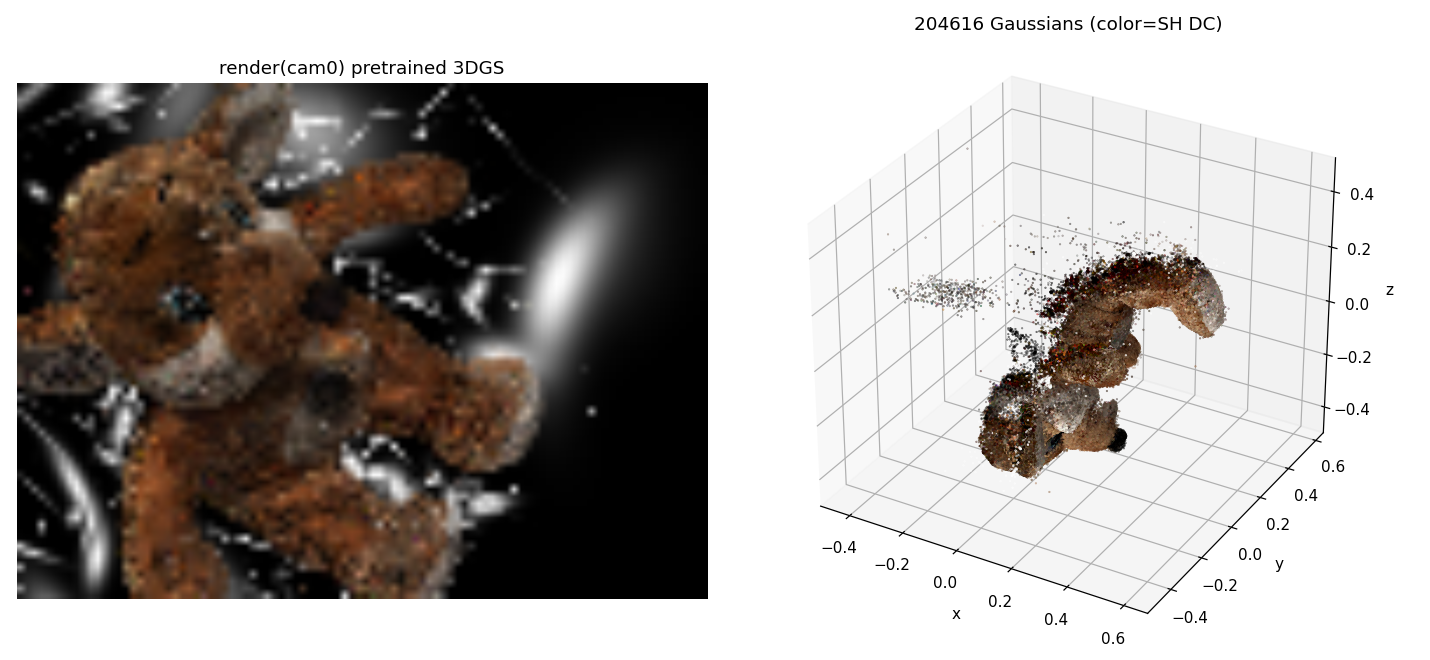

In [10]:
# ============ 6. RENDER (VISUAL 1) + GAUSSIAN CLOUD ============
cam0 = cams[0]
stride = EVAL_RENDER_STRIDE
while ((cam0.H // stride) * (cam0.W // stride)) > 20000:
    stride *= 2
log(f"render stride={stride}  ({cam0.W // stride}x{cam0.H // stride} rays)")

origins0, dirs0, (yy0, xx0) = cam0.rays(DEVICE, stride=stride)
log(f"rendering cam0 ({len(origins0)} rays)...")
pred_cols = []
with torch.no_grad():
    for s in range(0, len(origins0), EVAL_RENDER_BATCH_SIZE):
        o = origins0[s:s + EVAL_RENDER_BATCH_SIZE].to(DEVICE)
        d = dirs0[s:s + EVAL_RENDER_BATCH_SIZE].to(DEVICE)
        pred_cols.append(losses.render_rays(gauss_pretrained, o, d,
                                            cull_sigma=CULL_SIGMA, max_candidates=MAX_CANDIDATES).cpu())
rendered = torch.cat(pred_cols, dim=0)                       # (M,3)
n_y, n_x = len(range(0, cam0.H, stride)), len(range(0, cam0.W, stride))
img_pred = rendered.numpy().reshape(n_y, n_x, 3).clip(0, 1)

from PIL import Image as _PIL
_pil = _PIL.fromarray((img_pred * 255).astype(np.uint8)).resize((cam0.W, cam0.H), _PIL.BILINEAR)
img_pred_full = np.asarray(_pil, np.float32) / 255.0
np.save(RUN_BASE / "img_pred_cam0.npy", img_pred_full)

p1 = RUN_BASE / "step1_pretrained_render.png"
fig = plt.figure(figsize=(13, 6))
ax1 = fig.add_subplot(1, 2, 1); ax1.imshow(img_pred_full)
ax1.set_title("render(cam0) pretrained 3DGS"); ax1.axis("off")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
pos = gauss_pretrained.positions.detach().cpu().numpy()
col = gauss_pretrained.colors.detach().cpu().numpy()
plot_scatter_axes(ax2, pos, s=0.6, c=col, max_pts=200000)
ax2.set_title(f"{len(gauss_pretrained)} Gaussians (color=SH DC)")
fig.tight_layout(); fig.savefig(p1, dpi=110); plt.close(fig)
Show(p1, title="VISUAL 1 - pretrained render + cloud")


In [14]:
# ============ DIAGNOSTIC: roll/up-vector check + alternate convention test ============
def render_with_rotation_convention(cam, gauss, device, use_transpose):
    """Render cam0 twice: sekali dengan konvensi rotation-as-cam2world (default,
    seperti sekarang), sekali dengan rotation-as-world2cam langsung (tanpa transpose).
    Kalau versi kedua tampak tegak, berarti field 'rotation' di dataset kamu memang
    sudah world2cam, bukan cam2world seperti diasumsikan kode saat ini."""
    import copy
    cam2 = copy.deepcopy(cam)
    if use_transpose:
        # treat stored 'rotation' as world2cam directly -- undo the .T in loader
        cam2.R = cam2.R.T.copy()
        cam2.t = -cam2.R @ cam2.center
    stride = EVAL_RENDER_STRIDE
    while ((cam2.H // stride) * (cam2.W // stride)) > 20000:
        stride *= 2
    o, d, _ = cam2.rays(device, stride=stride)
    with torch.no_grad():
        cols = losses.render_rays(gauss, o.to(device), d.to(device),
                                   cull_sigma=CULL_SIGMA, max_candidates=MAX_CANDIDATES).cpu()
    ny, nx = len(range(0, cam2.H, stride)), len(range(0, cam2.W, stride))
    return cols.numpy().reshape(ny, nx, 3).clip(0, 1)

img_default = render_with_rotation_convention(cam0, gauss_pretrained, DEVICE, use_transpose=False)
img_alt     = render_with_rotation_convention(cam0, gauss_pretrained, DEVICE, use_transpose=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_default); axes[0].set_title("current (rotation = cam2world)"); axes[0].axis("off")
axes[1].imshow(img_alt);     axes[1].set_title("alternate (rotation = world2cam)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## Step C - Surface extraction (the part that works)
For every ray, `transmittance_crossing_points` finds the first depth where the
accumulated opacity transmittance crosses 0.5 (paper Eq. 3.2/3.3) and returns that
world point + a normal estimate. **These samples are the ground truth for SDF fitting**
and are already verified correct on scan105 - the downstream fit is where the
tunnel defect appears, and that is what Step D fixes.


In [15]:
# ============ 7. SURFACE EXTRACTION (T*=0.5 crossings) ============
RUN_DIR = RUN_BASE / f"{scan_label}-{RUN_HASH}"
RUN_DIR.mkdir(exist_ok=True)
cache_pt = RUN_DIR / "01_surface_samples.pt"

sampled_cams = cams
if len(sampled_cams) > SURF_MAX_CAMS:
    idxs = np.linspace(0, len(sampled_cams) - 1, SURF_MAX_CAMS).astype(int)
    cand_set = set(idxs.tolist())
    sampled_cams = [c for i, c in enumerate(sampled_cams) if i in cand_set]
    log(f"surface extraction: using {len(sampled_cams)}/{len(cams)} cameras (evenly spread)")

surface_points = surface_normals = None
if cache_pt.exists():
    ck = torch.load(cache_pt, map_location=DEVICE)
    if ck.get("run_hash") == RUN_HASH and ck.get("schema") == 2:
        surface_points, surface_normals = ck["points"], ck["normals"]
        log(f"[cache] loaded {len(surface_points)} surface samples from {cache_pt.name}")
    else:
        cache_pt.unlink()

if surface_points is None or surface_points.shape[0] == 0:
    log("extracting surface samples from ray crossings...")
    pts_l, nrm_l = [], []
    t0t = time.time()
    for ci, cam in enumerate(sampled_cams):
        origins, dirs, _ = cam.rays(DEVICE, stride=SURFACE_STRIDE)
        for s in range(0, len(origins), SURFACE_RAY_BATCH_SIZE):
            o = origins[s:s + SURFACE_RAY_BATCH_SIZE].to(DEVICE)
            d = dirs[s:s + SURFACE_RAY_BATCH_SIZE].to(DEVICE)
            p, n, _valid = transmittance.transmittance_crossing_points(
                gauss_pretrained, o, d, cull_sigma=CULL_SIGMA, max_candidates=MAX_CANDIDATES)
            pts_l.append(p.float().cpu()); nrm_l.append(n.float().cpu())
        if (ci + 1) % 4 == 0:
            log(f"  cam {ci + 1}/{len(sampled_cams)} "
                f"({sum(len(x) for x in pts_l)} samples, {time.time() - t0t:.0f}s)")
    surface_points = torch.cat(pts_l, dim=0)  if pts_l else torch.empty(0, 3)
    surface_normals = torch.cat(nrm_l, dim=0) if nrm_l else torch.empty(0, 3)
    utils.check_tensor("surface_points", surface_points)
    utils.check_tensor("surface_normals", surface_normals)
    torch.save(dict(run_hash=RUN_HASH, schema=2,
                    points=surface_points, normals=surface_normals), cache_pt)
    log(f"saved {len(surface_points)} samples -> {cache_pt.name}")

if surface_points.shape[0] == 0:
    raise RuntimeError("0 surface samples extracted - check opacity filter / camera sanity / cull radius")

surface_points_np = surface_points.float().detach().cpu().numpy()
surface_normals_np = surface_normals.float().detach().cpu().numpy()

from scipy.spatial import cKDTree
SURF_TREE = cKDTree(surface_points_np)

log(f"surface samples: {len(surface_points)} rays crossed T*=0.5 "
    f"(stride {SURFACE_STRIDE}, cull_sigma={CULL_SIGMA}, max_candidates={MAX_CANDIDATES})")
log(f"samples bbox: min={surface_points_np.min(0).round(3)}  max={surface_points_np.max(0).round(3)}")


[06:57:30] surface extraction: using 24/64 cameras (evenly spread)
[06:57:30] [cache] loaded 66611 surface samples from 01_surface_samples.pt
[06:57:30] surface samples: 66611 rays crossed T*=0.5 (stride 16, cull_sigma=4.0, max_candidates=4096)
[06:57:30] samples bbox: min=[-0.462 -0.612 -0.522]  max=[0.652 0.673 0.605]


== VISUAL 2 - surface samples ==


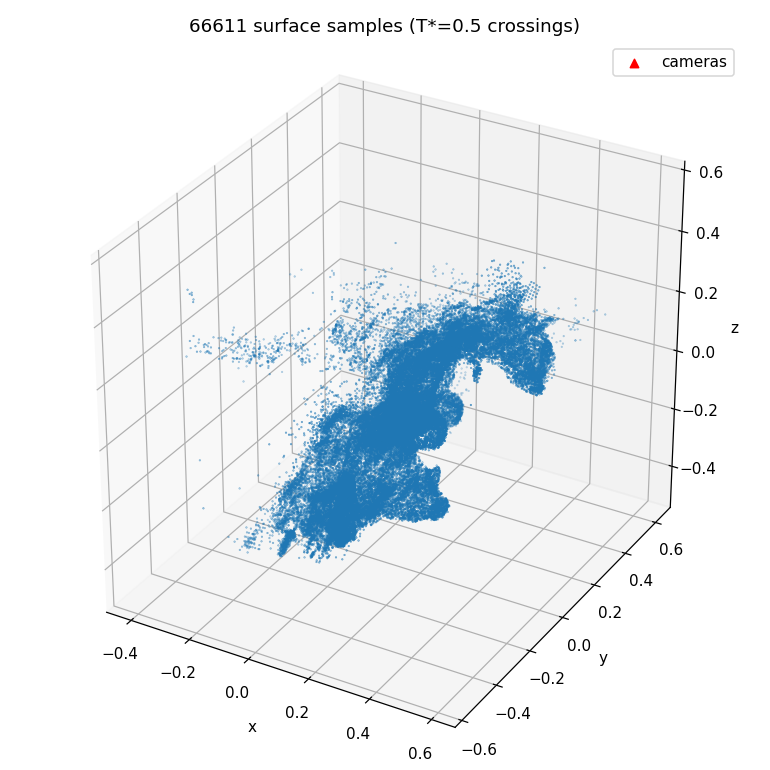

[06:57:31] projecting samples into cam0 (1:1 overlay)...
== VISUAL 3 - samples project 1:1 onto the picture (every sample should hit the bear) ==


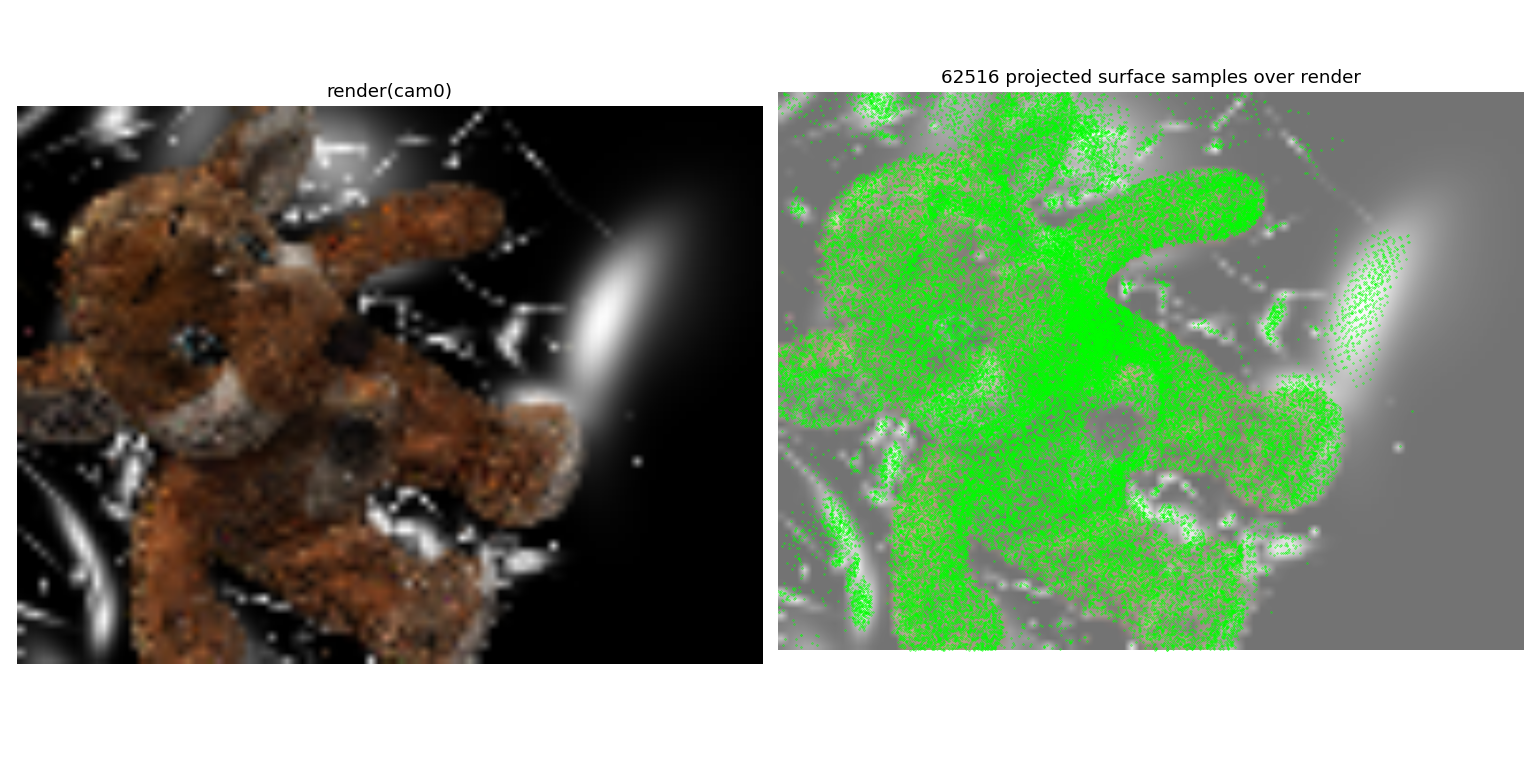

In [16]:
# ============ 8. VISUAL 2+3 - SAMPLE CLOUD + 1:1 PROJECTION OVERLAY ============
p2 = RUN_BASE / "step2_surface_samples.png"
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")
plot_scatter_axes(ax, surface_points_np, max_pts=250000, s=0.6)
centers = np.stack([c.center for c in cams]).astype(np.float32)
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], c="red", s=30, marker="^", label="cameras")
ax.legend()
ax.set_title(f"{len(surface_points)} surface samples (T*=0.5 crossings)")
fig.tight_layout(); fig.savefig(p2, dpi=110); plt.close(fig)
Show(p2, title="VISUAL 2 - surface samples")

log("projecting samples into cam0 (1:1 overlay)...")
u, v, z = project_to_camera(surface_points_np, cam0)
inside = (u >= 0) & (u < cam0.W) & (v >= 0) & (v < cam0.H)
u, v = u[inside], v[inside]
if len(u) > 120000:
    rng = np.random.default_rng(0)
    keep = rng.choice(len(u), 120000, replace=False)
    u, v = u[keep], v[keep]

p3 = RUN_BASE / "step3_samples_overlay.png"
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img_pred_full); axes[0].set_title("render(cam0)"); axes[0].axis("off")
axes[1].imshow(img_pred_full, alpha=0.55)
axes[1].scatter(u, v, s=0.4, c="lime", marker=".")
axes[1].set_title(f"{len(u)} projected surface samples over render")
axes[1].axis("off")
fig.tight_layout(); fig.savefig(p3, dpi=110); plt.close(fig)
Show(p3, title="VISUAL 3 - samples project 1:1 onto the picture (every sample should hit the bear)")


## Step D - SDF refinement WITH THE TUNNEL-DEFECT FIX
**Diagnosis (confirmed on scan105):** the surface samples are correct, but the fitted
SDF blends two real, near-touching surface sheets (about 0.003 units apart) into one
fold, so Marching Cubes stitches an extra *handle* (genus-1 tunnel) through the bear.

**Fix (active this run):**
1. **Real supervision batches.** 4096 surface samples per step (`S_BATCH`) instead of
   the old ~64, so the SDF stops getting stuck in an egg/blob plateau.
2. **Orientation disambiguation.** For each sampled point, compute the *local normal
   majority* via k-NN over the thousands of cached surface samples. Samples that
   oppose the local majority (the backwards-facing sheet inside the tunnel fold)
   are dropped, and a signed **normal-consistency penalty** pushes the SDF gradient
   to align to the *majority orientation*, so the two opposing sheets disambiguate into one.
3. Plus the standard terms: eikonal (volume + on-surface), zero-boundary and normal alignment.

The mesh is snapshot every `SNAPSHOT_EVERY` iterations so you can watch it converge.


In [18]:
# ============ 9. SDF NET, OPTIMIZERS, BOUNDS, DISAMBIGUATION HELPERS ============
import math

sdf_net = sdf.SDFNetwork(d_in=3, d_hidden=256, n_layers=8, radius_init=1.0, beta=100.0).to(DEVICE)
sdf_initial_state = {k: v.detach().clone() for k, v in sdf_net.state_dict().items()}

BMIN, BMAX = evaluation.compute_object_bbox(surface_points_np, margin=0.10)
log(f"SDF bounds: min={BMIN} max={BMAX}")

gauss_f = gauss_pretrained.clone_detached()
gauss_frozen_target = None
if USE_PHOTOMETRIC:
    gauss_frozen_target = losses.build_frozen_photometric_target(
        gauss_pretrained.clone_detached(), perturb_fraction=0.02,
        generator=torch.Generator(device="cpu"))

opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=LR_SDF)
opt_gauss = torch.optim.Adam([p for p in [gauss_f.positions, gauss_f.opacity,
                                          gauss_f.scales, gauss_f.rotations, gauss_f.colors]],
                             lr=LR_GAUSS)

def lr_scale(it, n, warm_frac=0.10, peak=1.0):
    if n <= 0:
        return peak
    warm = int(n * warm_frac)
    if it < warm:
        return peak * (it + 1) / max(1, warm)
    frac = (it - warm) / max(1, n - warm)
    return peak * 0.5 * (1.0 + math.cos(math.pi * frac))

def normalize_np(x):
    n = np.linalg.norm(x, axis=-1, keepdims=True)
    return x / (n + 1e-8)

def majority_normals(pts_np, nrm_np, k=DISAMB_K, cos_keep=COS_KEEP):
    """Recommended local normal majority around each sampled point, from the CACHED
    surface-sample cloud, and the majority-normal tensor.
    - Samples aligned with the majority keep their own normal.
    - Samples opposing the majority (e.g. the wrong sheet of the tunnel fold) are dropped.
    """
    k = min(k, len(SURF_TREE.data))
    _, idx = SURF_TREE.query(pts_np, k=k)
    idx = np.atleast_2d(idx)
    if idx.shape[1] == 1:
        idx = idx[:, 0]
    if idx.ndim == 1:
        nb_mean = surface_normals_np[idx].astype(np.float32)
    else:
        nb_mean = surface_normals_np[idx].astype(np.float32).mean(axis=1)
    majority = normalize_np(nb_mean)
    cos = (normalize_np(nrm_np) * majority).sum(-1)
    keep = cos >= cos_keep
    out_n = np.where(keep[:, None], nrm_np, majority).astype(np.float32)
    return keep, torch.from_numpy(out_n).float().to(DEVICE)

def normal_consistency_penalty(grad_s, target_normals, eps=1e-4):
    """SIGNED consistency: drives grad f towards the MAJORITY orientation (line + sign),
    unlike normal_and_boundary_loss which only aligns the unsigned line. This is the
    term that disambiguates the two opposing sheets in the tunnel region. The 'eps' arg
    exists for API symmetry; do not inflate it (it would denormalize the prediction).
    """
    pred = grad_s / (grad_s.norm(dim=-1, keepdim=True) + eps)
    return (1.0 - (pred * target_normals).sum(-1)).clamp(min=0.0).mean()

log("prepared: SDFNet(8 x 256) + Adam optimizers + disambiguation helpers")


[06:59:14] SDF bounds: min=[-0.5733979  -0.74010605 -0.6350015 ] max=[0.7636941 0.8018203 0.7173027]
[06:59:14] prepared: SDFNet(8 x 256) + Adam optimizers + disambiguation helpers


  [mesh] filled 2 hole(s) (<= 150 edges each)
  [mesh] WARNING: 3 hole(s) exceed 150 edges, left open
[topo] grid 128 (PRE-refinement, geometric-init only): V=57053 F=112538 watertight=False euler=-1 genus=None boundary_edges=1570


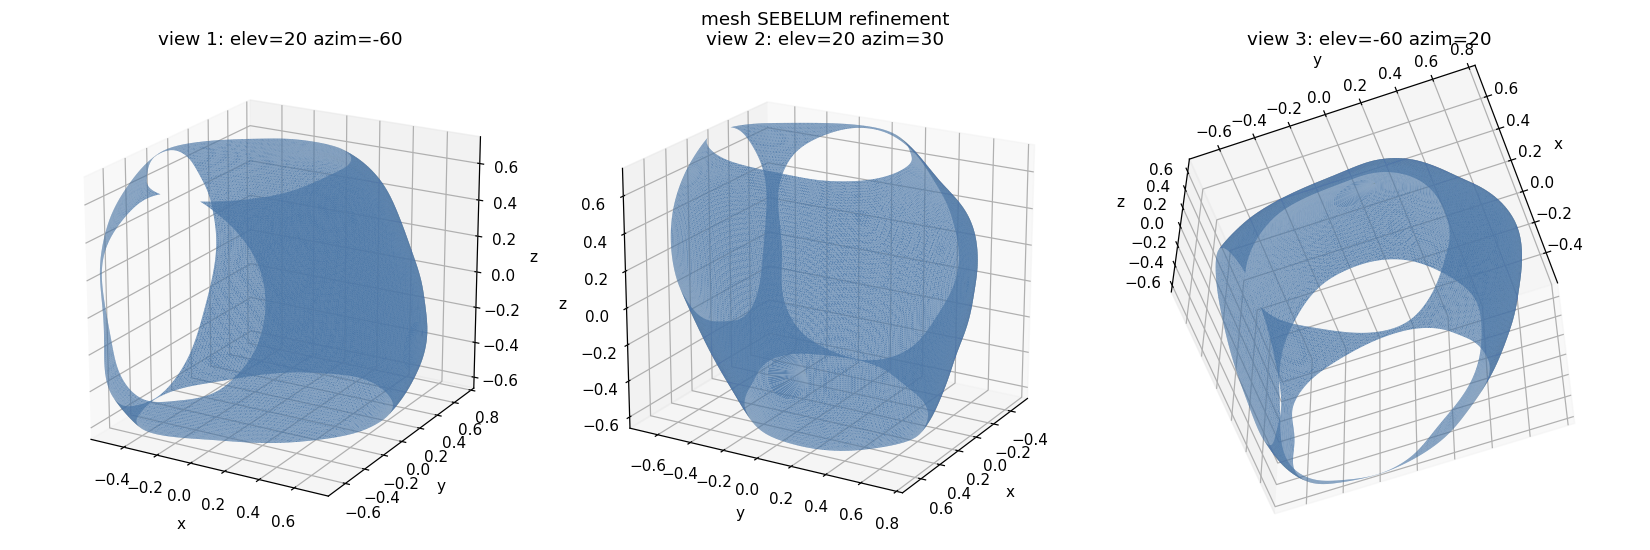

In [19]:
# ============ CEK CEPAT: mesh langsung dari SDF net TANPA refinement ============
# reset ke state awal (geometric-init, sebelum training loop / cell 15 dijalankan)
sdf_net.load_state_dict(sdf_initial_state)
sdf_net.eval()

res_check = 128  # resolusi kecil biar cepat, naikin kalau mau lebih detail
v0, f0 = mesh_mod.extract_mesh(sdf_net, BMIN, BMAX, res_check, DEVICE)

if v0 is None:
    log(f"grid {res_check}: no zero-crossing - SDF awal tidak melewati nol di bounding box ini")
else:
    m0 = mesh_mod.postprocess(v0, f0, keep_only_largest=True,
                               max_hole_edges=150, laplacian_smooth=False)[0]
    mesh_mod.save_mesh(m0, RUN_DIR / f"{res_check}_mesh_PRE_refinement.ply")
    topo(m0, f"grid {res_check} (PRE-refinement, geometric-init only)")
    mesh3view(m0, RUN_DIR / f"{res_check}_mesh_PRE_refinement.png", title="mesh SEBELUM refinement")
    Show(RUN_DIR / f"{res_check}_mesh_PRE_refinement.png")

In [ ]:
# ============ 10. TRAINING LOOP (with disambiguation + real supervision) ============
CP_PATH = RUN_DIR / "train_checkpoint.pt"
FLAG_HASH = hashlib.sha1(str(dict(DISAMBIGUATE=DISAMBIGUATE, COS_KEEP=COS_KEEP,
                                  S_BATCH=S_BATCH, N_ITERS=N_ITERS, RUN_HASH=RUN_HASH)).encode()).hexdigest()[:8]
log(f"flag hash: {FLAG_HASH}")

start_it = 0
loss_hist = {"total": [], "eik": [], "surf_eik": [], "nb": [], "nc": [], "n_surf": []}
snapshots = {}
tm0 = time.time()

if CP_PATH.exists():
    try:
        ck = torch.load(CP_PATH, map_location=DEVICE)
        if (ck.get("run_hash") == RUN_HASH and ck.get("flag_hash") == FLAG_HASH
                and ck.get("step", -1) < N_ITERS - 1):
            sdf_net.load_state_dict(ck["sdf_state"])
            opt_sdf.load_state_dict(ck["optim_sdf"])
            opt_gauss.load_state_dict(ck["optim_gauss"])
            start_it = ck["step"] + 1
            loss_hist = ck["loss_history"]
            snapshots = ck.get("snapshots", {})
            log(f"[resume] continuing from iteration {start_it}")
        else:
            CP_PATH.unlink()
            log("[fresh] checkpoint mismatch -> restarting training")
    except Exception as e:
        log(f"[fresh] checkpoint unreadable ({e!r}) -> restarting training")
        if CP_PATH.exists():
            CP_PATH.unlink()

n_surf_all = len(surface_points_np)
for it in range(start_it, N_ITERS):
    lr = LR_SDF * lr_scale(it, N_ITERS)
    for g in opt_sdf.param_groups:
        g["lr"] = lr
    for g in opt_gauss.param_groups:
        g["lr"] = LR_GAUSS * lr_scale(it, N_ITERS)

    # ---- sample a real supervision batch from the cached surface cloud ----
    idx = np.random.randint(0, n_surf_all, size=S_BATCH)
    p = surface_points_np[idx].astype(np.float32)
    nn = surface_normals_np[idx].astype(np.float32)

    if DISAMBIGUATE:
        keep, n_major = majority_normals(p, nn)
        p = p[keep]
        n_major = n_major[keep]
        if len(p) < max(64, S_BATCH // 8):
            p = surface_points_np[idx].astype(np.float32)
            n_major = torch.from_numpy(surface_normals_np[idx].astype(np.float32)).float().to(DEVICE)
    else:
        n_major = torch.from_numpy(nn).float().to(DEVICE)

    pt = torch.from_numpy(p).float().to(DEVICE)
    f_s, g_s = sdf_net.gradient(pt)
    l_nb = losses.normal_and_boundary_loss(f_s, g_s, n_major)
    l_surf = losses.eikonal_loss(g_s)

    bmin_t = torch.tensor(BMIN, device=DEVICE, dtype=torch.float32)
    bmax_t = torch.tensor(BMAX, device=DEVICE, dtype=torch.float32)
    dom = bmin_t + torch.rand(DOMAIN_BATCH, 3, device=DEVICE) * (bmax_t - bmin_t)
    _, g_d = sdf_net.gradient(dom)
    l_eik = losses.eikonal_loss(g_d)

    l_nc = normal_consistency_penalty(g_s, n_major) if DISAMBIGUATE else torch.zeros((), device=DEVICE)
    total = LAMBDA_E * l_eik + LAMBDA_SURF_E * l_surf + LAMBDA_N * l_nb + LAMBDA_NC * l_nc

    opt_sdf.zero_grad(set_to_none=True)
    opt_gauss.zero_grad(set_to_none=True)
    total.backward()
    torch.nn.utils.clip_grad_norm_(sdf_net.parameters(), 10.0)
    opt_sdf.step()
    opt_gauss.step()

    with torch.no_grad():
        loss_hist["total"].append(float(total.item()))
        loss_hist["eik"].append(float(l_eik.item()))
        loss_hist["surf_eik"].append(float(l_surf.item()))
        loss_hist["nb"].append(float(l_nb.item()))
        loss_hist["nc"].append(float(l_nc.item()))
        loss_hist["n_surf"].append(len(p))

    if it % 100 == 0 or it == N_ITERS - 1:
        el = time.time() - tm0
        print(f"[{it:5d}/{N_ITERS}] total={total.item():.5f} eik={l_eik.item():.4f} "
              f"suiteik={l_surf.item():.4f} nb={l_nb.item():.5f} nc={l_nc.item():.4f} "
              f"n_surf={len(p)} lr={lr:.2e} ({el:.0f}s)")

    if (it + 1) % SNAPSHOT_EVERY == 0 or it == N_ITERS - 1:
        v, f = mesh_mod.extract_mesh(sdf_net, BMIN, BMAX, SNAP_RES, DEVICE)
        if v is not None:
            snapshots[it] = (v, f)
            log(f"  snapshot it={it} -> {len(v)} verts / {len(f)} faces")

    if (it + 1) % CHECKPOINT_EVERY == 0 or it == N_ITERS - 1:
        _tmp = RUN_DIR / "train_checkpoint.pt.tmp"
        torch.save(dict(run_hash=RUN_HASH, flag_hash=FLAG_HASH, step=it,
                        sdf_state=sdf_net.state_dict(),
                        optim_sdf=opt_sdf.state_dict(), optim_gauss=opt_gauss.state_dict(),
                        loss_history=loss_hist, snapshots=snapshots), _tmp)
        os.replace(_tmp, CP_PATH)

torch.save(dict(state=sdf_net.state_dict(),
                config=dict(n_iters=N_ITERS, s_batch=S_BATCH, disambiguate=DISAMBIGUATE, cos_keep=COS_KEEP)),
           RUN_DIR / "03_sdf_final.pt")
log(f"training done {time.time() - tm0:.0f}s total; final sdf -> 03_sdf_final.pt")


In [ ]:
# ============ 11. VISUAL 4 - LOSS CURVES + CONVERGENCE STRIP ============
p4a = RUN_BASE / "step4a_loss_curves.png"
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
for k, c in [("total", "black"), ("eik", "tab:blue"), ("nb", "tab:red"), ("nc", "tab:green")]:
    ax.plot(loss_hist[k], label=k, color=c, lw=0.8)
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("loss (log)")
ax.legend()
ax.set_title(f"training losses ({N_ITERS} iters, S_BATCH={S_BATCH}, disambiguate={DISAMBIGUATE})")
fig.tight_layout(); fig.savefig(p4a, dpi=110); plt.close(fig)
Show(p4a, title="VISUAL 4a - loss curves")

p4b = RUN_BASE / "step4b_convergence_strip.png"
its = sorted(snapshots.keys())
n = len(its)
if n:
    cols = min(n, 6)
    rows = -(-n // cols)
    fig = plt.figure(figsize=(4 * cols, 4 * rows))
    for i, it in enumerate(its):
        ax = fig.add_subplot(rows, cols, i + 1, projection="3d")
        v, f = snapshots[it]
        plot_mesh_axes(ax, v, f, max_faces=60000)
        ax.set_title(f"it {it}")
        ax._axis3don = False
    fig.suptitle("SDF convergence: mesh snapshots (grid 96)")
    fig.tight_layout(); fig.savefig(p4b, dpi=110); plt.close(fig)
    Show(p4b, title="VISUAL 4b - convergence strip")
else:
    print("no snapshots recorded")


## Step E - Marching Cubes at 160 AND 256
Same SDF, two grid resolutions. We always report watertightness, genus and boundary
edge count per resolution - this is where the old run produced the genus-1 tunnel.

`REMOVE_DOCUMENTED_BRIDGE = False` by default: we report the honest topology.
Set it to `True` as a last resort to voxel-close any remaining handle (logged loud).


In [ ]:
# ============ 12. MARCHING CUBES at 160 & 256 + RAW TOPOLOGY ============
raw_meshes = {}
for res in MESH_GRIDS:
    log(f"extracting mesh at grid {res}...")
    v, f = mesh_mod.extract_mesh(sdf_net, BMIN, BMAX, res, DEVICE)
    if v is None:
        log(f"  grid {res}: no zero-crossing in the volume - SDF never changed sign!")
        continue
    m = mesh_mod.postprocess(v, f, keep_only_largest=True, max_hole_edges=150,
                             laplacian_smooth=False)[0]
    mesh_mod.save_mesh(m, RUN_DIR / f"{res}_mesh_raw.ply")
    topo(m, f"grid {res} (raw, keep-largest, small-hole fill)")
    raw_meshes[res] = m
    log(f"  saved -> {res}_mesh_raw.ply")


In [ ]:
# ============ 13. (OPTIONAL) DOCUMENTED BRIDGE REMOVAL + VISUAL 5 ============
def close_handle_voxel(m, res=256):
    """Voxel-close: flood-fill internal empty voxel cavities (a through-handle is one)
    and re-run marching cubes on the solid. Documented, visible engineering fallback."""
    from scipy.ndimage import binary_fill_holes
    import skimage
    ext = (m.bounds[1] - m.bounds[0]).max()
    pitch = float(ext) / res
    vox = m.voxelized(pitch=pitch)
    mat = np.asarray(vox.matrix, dtype=bool)
    solid = binary_fill_holes(mat)
    added = int(solid.sum()) - int(mat.sum())
    print(f"  [bridge-removal] voxelization pitch={pitch:.5f}; "
          f"flood-filled {added} solid voxels (tunnel cavity closed)")
    verts, faces, _, _ = skimage.measure.marching_cubes(solid.astype(np.float32), level=0.5,
                                                        spacing=(pitch, pitch, pitch))
    origin = np.asarray(vox.transform[:3, 3], np.float32)
    return (verts + origin).astype(np.float32), faces.astype(np.int64)

final_meshes = {}
for res, m in raw_meshes.items():
    t = topo(m, f"grid {res}")
    final_meshes[res] = m
    if REMOVE_DOCUMENTED_BRIDGE and t["genus"] is not None and t["genus"] > 0:
        try:
            v, f = close_handle_voxel(m, res=max(128, res))
            m2, _ = mesh_mod.postprocess(v, f, keep_only_largest=True, max_hole_edges=150)
            mesh_mod.save_mesh(m2, RUN_DIR / f"{res}_mesh_bridged.ply")
            topo(m2, f"grid {res} AFTER voxel-close")
            final_meshes[res] = m2
            log(f"  REMOVE_DOCUMENTED_BRIDGE=TRUE applied at grid {res} (see topo above)")
        except Exception as e:
            log(f"  bridge-removal failed at grid {res}: {e!r}")
    elif REMOVE_DOCUMENTED_BRIDGE:
        log(f"  grid {res} already genus-0 -> bridge removal not needed")

vis_res = max(final_meshes.keys()) if final_meshes else None
if vis_res is not None:
    m_viz = final_meshes[vis_res]
    mesh_mod.save_mesh(m_viz, RUN_DIR / f"{vis_res}_mesh_final.ply")
    p5 = RUN_BASE / "step5_extracted_mesh.png"
    mesh3view(m_viz, p5, title=f"extracted mesh (MC grid {vis_res}, V={len(m_viz.vertices)})")
    Show(p5, title="VISUAL 5 - extracted mesh 3-view (equal aspect)")
else:
    log("no mesh produced")
    m_viz = None


In [ ]:
# ============ 14. VISUAL 6 - MESH PROJECTED ONTO THE RENDER ============
u_overlay = np.array([], dtype=np.float32)
v_overlay = np.array([], dtype=np.float32)
if vis_res is not None:
    m_viz = final_meshes[vis_res]
    mv = np.asarray(m_viz.vertices, np.float32)
    u, v, z = project_to_camera(mv, cam0)
    ok = (z > 0)
    u, v, z = u[ok], v[ok], z[ok]
    inside = (u >= 0) & (u < cam0.W) & (v >= 0) & (v < cam0.H)
    u, v = u[inside], v[inside]
    if len(u) > 100000:
        rng = np.random.default_rng(1)
        keep = rng.choice(len(u), 100000, replace=False)
        u, v = u[keep], v[keep]
    u_overlay, v_overlay = u, v
    p6 = RUN_BASE / "step6_mesh_overlay.png"
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(img_pred_full); axes[0].set_title("render(cam0)"); axes[0].axis("off")
    axes[1].imshow(img_pred_full, alpha=0.55)
    axes[1].scatter(u, v, s=0.3, c="deepskyblue", marker=".")
    axes[1].set_title(f"mesh (grid {vis_res}) projected onto render")
    axes[1].axis("off")
    fig.tight_layout(); fig.savefig(p6, dpi=110); plt.close(fig)
    Show(p6, title="VISUAL 6 - extracted mesh silhouette vs picture")
else:
    log("no mesh to overlay")


## Optional - DTU ground-truth comparison (best effort)
If the `dtu-groundtruth` dataset contains a GT mesh it is loaded, roughly aligned
(centroid + per-axis scale), and evaluated with bidirectional Chamfer distance and
F-score. If anything fails, this step is skipped gracefully - it never blocks the
rest of the notebook.


In [ ]:
# ============ 15. GT (best effort) + VISUAL 7 + RESULTS JSON ============
gt_results = {}
try:
    gt_path = evaluation.discover_gt_mesh(search_root_gt or ".")
    if gt_path is None:
        log("no GT mesh found - skip")
    else:
        log(f"GT mesh: {gt_path}")
        gt_mesh = evaluation.load_gt_mesh(gt_path)
        if hasattr(gt_mesh, "vertices") and getattr(gt_mesh, "faces", None) is not None:
            gt_pts = evaluation.sample_surface(gt_mesh, 100000).astype(np.float32)
            sc = surface_points_np.max(0) - surface_points_np.min(0)
            gc = gt_pts.max(0) - gt_pts.min(0)
            scale = (sc / (gc + 1e-8)).astype(np.float32)
            gt_center = gt_pts.mean(0)
            pred_center = surface_points_np.mean(0)
            gt_verts_aligned = (np.asarray(gt_mesh.vertices, np.float64) - gt_center) * scale + pred_center
            gt_aligned = trimesh.Trimesh(vertices=gt_verts_aligned.astype(np.float64),
                                         faces=np.asarray(gt_mesh.faces).astype(np.int64))
            if vis_res is not None:
                pred_mesh = final_meshes[vis_res]
            else:
                pred_mesh = trimesh.Trimesh(vertices=surface_points_np, faces=np.zeros((0, 3), dtype=np.int64))
            cd = evaluation.chamfer_distance(pred_mesh, gt_aligned, n_points=30000, seed=3,
                                             gt_crop_bbox=(BMIN, BMAX))
            fs = evaluation.f_score(pred_mesh, gt_aligned, thresholds=(0.001, 0.005),
                                    n_points=30000, seed=3, gt_crop_bbox=(BMIN, BMAX))
            gt_results = {k: v for k, v in cd.items() if not k.startswith("_")}
            gt_results["f_score"] = fs
            log(f"GT: chamfer={cd['chamfer_distance']:.5f}  " +
                " ".join(f"F1@{k}={v['f1']:.3f}" for k, v in fs.items()))

            gv = np.asarray(gt_aligned.vertices, np.float32)
            u2, v2, z2 = project_to_camera(gv, cam0)
            ok2 = (z2 > 0) & (u2 >= 0) & (u2 < cam0.W) & (v2 >= 0) & (v2 < cam0.H)
            p7 = RUN_BASE / "step7_gt_overlay.png"
            fig, ax = plt.subplots(1, 1, figsize=(7, 7))
            ax.imshow(img_pred_full, alpha=0.5)
            ax.scatter(u2[ok2], v2[ok2], s=0.2, c="orange", marker=".")
            ax.scatter(u_overlay, v_overlay, s=0.2, c="deepskyblue", marker=".")
            ax.set_title("GT (orange) + extracted mesh (blue) over render")
            ax.axis("off")
            fig.tight_layout(); fig.savefig(p7, dpi=110); plt.close(fig)
            Show(p7, title="VISUAL 7 - GT overlay")
        else:
            log("GT loaded but has no vertices - skip")
except Exception as e:
    log(f"GT evaluation skipped: {e!r}")

# ---- results manifest ----
topo_report = {}
for res, m in raw_meshes.items():
    topo_report[str(res)] = topo(m, f"grid {res}")
results = dict(
    run_hash=RUN_HASH, scan=scan_label, ply_path=str(ply_path), cam_source=cam_src,
    synthetic_demo=bool(USE_SYNTHETIC_DEMO),
    config=dict(seed=SEED, opacity_thresh=OPACITY_THRESH, cull_sigma=CULL_SIGMA,
                max_candidates=MAX_CANDIDATES, surface_stride=SURFACE_STRIDE,
                n_surface_samples=int(len(surface_points)), n_iters=N_ITERS, s_batch=S_BATCH,
                domain_batch=DOMAIN_BATCH, lambda_e=LAMBDA_E, lambda_surf_e=LAMBDA_SURF_E,
                lambda_n=LAMBDA_N, lambda_nc=LAMBDA_NC, disambiguate=DISAMBIGUATE,
                cos_keep=COS_KEEP, disamb_k=DISAMB_K, lr_sdf=LR_SDF,
                remove_documented_bridge=REMOVE_DOCUMENTED_BRIDGE),
    gaussian_counts=dict(full=int(len(gauss_full)), filtered=int(len(gauss_pretrained))),
    topology=topo_report,
    gt=gt_results if gt_results else None,
    final_loss=loss_hist["total"][-1] if loss_hist["total"] else None,
)
(RUN_DIR / "results.json").write_text(json.dumps(results, indent=2, default=str), encoding="utf-8")
log("results.json written -> " + str(RUN_DIR / "results.json"))

print()
for k, t in topo_report.items():
    genus = t["genus"]
    if genus is not None and genus == 0:
        print(f"  OK  grid {k}: watertight genus-0  ({t['boundary_edges']} boundary edges)")
    elif genus is not None:
        print(f"  !!  grid {k}: genus={genus} - handle present (raise N_ITERS in section 3, "
              f"or set REMOVE_DOCUMENTED_BRIDGE=True and re-run from section 12)")
    else:
        print(f"  ??  grid {k}: not watertight / unbuildable ({t['boundary_edges']} boundary edges)")


In [ ]:
# ============ 16. FINAL MOSAIC + KAGGLE CACHE CLEANUP ============
print("---- FINAL ARTIFACTS ----")
for f in sorted(RUN_BASE.glob("step*.png")):
    print("  ", f.name)
print("  run dir:", RUN_DIR)
for f in sorted(RUN_DIR.iterdir()):
    print("  ", f.name)

mosaic = RUN_BASE / "final_summary.png"
steps = sorted(RUN_BASE.glob("step*.png"))
if steps:
    import matplotlib.image as mpimg
    cols = min(len(steps), 4)
    rows = -(-len(steps) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for i, f in enumerate(steps):
        mp_im = mpimg.imread(f)
        axes[i].imshow(mp_im)
        axes[i].axis("off")
        axes[i].set_title(f.stem)
    for i in range(len(steps), len(axes)):
        axes[i].axis("off")
    fig.suptitle("SDF-GS Refine - full visual pipeline")
    fig.tight_layout(); fig.savefig(mosaic, dpi=100); plt.close(fig)
    Show(mosaic, title="Final summary")

print()
print("---- CLEANUP ----")
freed = 0
import shutil
for p in DATASET_CACHES:
    if p.exists():
        sz = sum(os.path.getsize(os.path.join(dp, f))
                 for dp, _, fs in os.walk(p) for f in fs)
        shutil.rmtree(p)
        freed += sz
        print(f"  removed {p} ({sz / 2**20:.0f} MB)")
kaggle_cache = Path.home() / ".cache" / "kagglehub"
if kaggle_cache.exists():
    sz = sum(os.path.getsize(os.path.join(dp, f))
             for dp, _, fs in os.walk(kaggle_cache) for f in fs)
    shutil.rmtree(kaggle_cache)
    freed += sz
    print(f"  removed kagglehub cache dir ({sz / 2**20:.0f} MB)")
print(f"  total freed: {freed / 2**20:.0f} MB")
print("  kept (persistent):", RUN_BASE)


## Done - how to read this run
1. **`step1`** = the appearance target. Your final mesh must reproduce this silhouette.
2. **`step2/3`** = surface samples (the correct part). All samples should lie on the bear.
3. **`step4`** = SDF convergence. A healthy run shows the zero-level mesh emerging cleanly
   (no egg/blob plateau, because supervision is now 4096 samples/step).
4. **`step5/6`** = the extracted mesh. Success condition: **watertight genus-0 at 160 and 256**,
   and the silhouette matches `step1`.
5. If genus>0 remains after a full run: raise `N_ITERS` in section 3, or set
   `REMOVE_DOCUMENTED_BRIDGE = True` (it is logged, never silent).

All numbers live in `run_artifacts/<scan>-<hash>/results.json`. Paste that file plus the
`.png` thumbnails back here to continue debugging.
